# Community detection on the leak-free backbone: baselines, stability, K sweep, characterization, temporal dynamics



In [1]:
# ==== 0. Environment and configuration =============================================
import os, sys, json, time, warnings, subprocess
warnings.filterwarnings("ignore")
IN_COLAB = "google.colab" in sys.modules
SMOKE_TEST = bool(int(os.environ.get("HOD_SMOKE", "0")))
for pkg, mod in (("pymetis", "pymetis"), ("leidenalg", "leidenalg"), ("python-igraph", "igraph")):
    try: __import__(mod)
    except ImportError: subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg])

CONFIG = dict(
    BASE_DIR = "/content/drive/MyDrive/PhD/reddit_opinion_research",
    ITEM_KEYS = {}, OUT_DIR = None,
    # ---- backbones (identical training setup to notebooks 05/06/09 v4, no author features) ----------
    BACKBONES = {"hetero": "ssm_tree_hetero06", "lite": "ssm_tree"},
    SEEDS = [0, 1, 2, 3, 4],
    D_MODEL = 128, N_LAYERS = 4, N_STATE = 16, DROPOUT = 0.0, LR = 1e-3, WD = 0.01, BATCH_SIZE = 32,
    MAX_EPOCHS = 30, PATIENCE = 5, BATCH_TOKENS = 8192, AMP = False, SCAN_MODE = "pjump", AUTHOR_FEATURES = "none",
    # ---- DMoN (notebook 06) ------------------------------------------------------------------------
    K = 12, DMON_EPOCHS = 300, DMON_LR = 1e-2, DMON_WD = 1e-4,
    K_SWEEP = [4, 6, 8, 10, 12, 15, 20, 25, 30], SWEEP_SEEDS = [0, 1, 2],
    # ---- characterization -----------------------------------------------------------------------
    TOP_TERMS = 12, MIN_DF = 10, MAX_FEATURES = 30000,
)
if SMOKE_TEST:
    CONFIG.update(BASE_DIR="/tmp/hod_smoke09", SEEDS=[0, 1], D_MODEL=32, N_LAYERS=2, N_STATE=8, BATCH_SIZE=16,
                  MAX_EPOCHS=2, PATIENCE=1, K=4, DMON_EPOCHS=30, K_SWEEP=[2, 4, 6], SWEEP_SEEDS=[0, 1], MIN_DF=1)
elif IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
if CONFIG["OUT_DIR"] is None:
    CONFIG["OUT_DIR"] = os.path.join(CONFIG["BASE_DIR"], "processed_v2", "results", "nb11")
OUT = CONFIG["OUT_DIR"]; os.makedirs(f"{OUT}/runs", exist_ok=True)
print(json.dumps(CONFIG, indent=1, default=str))


Mounted at /content/drive
{
 "BASE_DIR": "/content/drive/MyDrive/PhD/reddit_opinion_research",
 "ITEM_KEYS": {},
 "OUT_DIR": "/content/drive/MyDrive/PhD/reddit_opinion_research/processed_v2/results/nb11",
 "BACKBONES": {
  "hetero": "ssm_tree_hetero06",
  "lite": "ssm_tree"
 },
 "SEEDS": [
  0,
  1,
  2,
  3,
  4
 ],
 "D_MODEL": 128,
 "N_LAYERS": 4,
 "N_STATE": 16,
 "DROPOUT": 0.0,
 "LR": 0.001,
 "WD": 0.01,
 "BATCH_SIZE": 32,
 "MAX_EPOCHS": 30,
 "PATIENCE": 5,
 "BATCH_TOKENS": 8192,
 "AMP": false,
 "SCAN_MODE": "pjump",
 "AUTHOR_FEATURES": "none",
 "K": 12,
 "DMON_EPOCHS": 300,
 "DMON_LR": 0.01,
 "DMON_WD": 0.0001,
 "K_SWEEP": [
  4,
  6,
  8,
  10,
  12,
  15,
  20,
  25,
  30
 ],
 "SWEEP_SEEDS": [
  0,
  1,
  2
 ],
 "TOP_TERMS": 12,
 "MIN_DF": 10,
 "MAX_FEATURES": 30000
}


## Shared code (`hod_core.py`)

In [2]:
%%writefile hod_core.py
# hod_core.py -- shared code for notebooks 09 (baselines) and 10 (parallel tree scan).
# Written to disk by the first code cell of each notebook so both notebooks use identical code.
import os, glob, json, math, time, random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

SENT_CLASSES = ["Negative", "Neutral", "Positive"]
EMO_CLASSES = ["Anger", "Joy", "Neutral", "Sadness", "Surprise"]   # Fear merged into Sadness
REL_ROOT, REL_POST, REL_COMMENT = 0, 1, 2
IGNORE = -100
N_REL = 3
BATCH_SIZE = None       # hyperedges per batch (notebook 05: 32); None = token-budget batching
DEFAULT_FEAT = "clean"  # author-feature bank used by models that don't name one ("none" = no author features)
FEATURE_BANK = {}       # name -> torch tensor [n_authors + 1, F] (last row = zeros for unknown authors)


def set_feature_bank(banks, device):
    """banks: {"clean": ndarray [n_authors, F], "leaky": ndarray [...], ...}. Models pick one via MODEL_SPECS."""
    FEATURE_BANK.clear()
    for name, mat in banks.items():
        m = np.asarray(mat, dtype=np.float32)
        FEATURE_BANK[name] = torch.from_numpy(np.vstack([m, np.zeros((1, m.shape[1]), np.float32)])).to(device)


def set_node_features(mat, device):
    """Backward-compatible single-matrix setter (registers it as the 'clean' bank)."""
    set_feature_bank({} if mat is None else {"clean": mat}, device)


def signed_log1p(x):
    return np.sign(x) * np.log1p(np.abs(x))


def build_author_features(text_corpus, temporal_edges, author_to_idx, cutoff=np.inf, sent_label_by_doc=None,
                          use_score=True):
    """Notebook 01b/04 author features, restricted to documents (and reply edges) created before `cutoff`.
    Definitions (01b): out_degree / in_degree = number of reply edges sent / received (self-replies excluded);
    n_posts / n_comments = documents authored; avg_score = mean Reddit score of the author's documents.
    If sent_label_by_doc is given (numeric -1/0/+1 per corpus row), avg_sentiment_score is appended (notebook 04's
    leaky column -- only used to verify the reconstruction). Transform: signed log1p, then z-score over authors."""
    tc = text_corpus[text_corpus["created_utc"] < cutoff]
    te = temporal_edges[temporal_edges["created_utc"] < cutoff]
    idx = pd.Index(list(author_to_idx.keys()))
    df = pd.DataFrame(index=idx)
    df["out_degree"] = te.groupby("source_author").size()
    df["in_degree"] = te.groupby("target_author").size()
    is_post = tc["parent_doc_id"].isna()
    df["n_posts"] = tc[is_post].groupby("author_hash").size()
    df["n_comments"] = tc[~is_post].groupby("author_hash").size()
    cols = ["out_degree", "in_degree", "n_posts", "n_comments"]
    if use_score and "score" in tc.columns:
        df["avg_score"] = tc.groupby("author_hash")["score"].mean(); cols.append("avg_score")
    if sent_label_by_doc is not None:
        lab = pd.Series(sent_label_by_doc, index=text_corpus.index)[tc.index]
        df["avg_sentiment_score"] = lab.groupby(tc["author_hash"]).mean(); cols.append("avg_sentiment_score")
    df = df[cols].fillna(0.0)
    order = np.argsort([author_to_idx[a] for a in df.index])
    X = signed_log1p(df.to_numpy(np.float64)[order])
    X = (X - X.mean(0)) / (X.std(0) + 1e-6)
    active = int((df[["n_posts", "n_comments"]].sum(1) > 0).sum())
    return X.astype(np.float32), cols, active


def reply_edges_from_corpus(tc):
    """Fallback when temporal_edges.parquet is unavailable: author->parent-author reply edges from text_corpus."""
    auth = tc.set_index("doc_id")["author_hash"]
    e = tc[tc["parent_doc_id"].notna()][["author_hash", "parent_doc_id", "created_utc"]].copy()
    e["target_author"] = e["parent_doc_id"].map(auth)
    e = e[e["target_author"].notna() & (e["target_author"] != e["author_hash"])]
    return e.rename(columns={"author_hash": "source_author"})[["source_author", "target_author", "created_utc"]]


def configure(sent_classes=None, emo_classes=None, n_rel=None, batch_size=None, default_feat=None):
    """Set class lists / number of relation types / batch size / default author features."""
    global SENT_CLASSES, EMO_CLASSES, N_REL, BATCH_SIZE, DEFAULT_FEAT
    if default_feat is not None: DEFAULT_FEAT = default_feat
    if batch_size is not None: BATCH_SIZE = int(batch_size)
    if sent_classes is not None: SENT_CLASSES = list(sent_classes)
    if emo_classes is not None: EMO_CLASSES = list(emo_classes)
    if n_rel is not None: N_REL = int(n_rel)


# =====================================================================================
# 1. Artifact discovery and loading
# =====================================================================================
def find_file(base_dir, patterns, required=True, exclude=()):
    hits = []
    for pat in patterns:
        hits += glob.glob(os.path.join(base_dir, "**", pat), recursive=True)
    hits = sorted({h for h in hits if not any(e in h for e in exclude)}, key=lambda p: (len(p), p))
    if not hits:
        if required:
            raise FileNotFoundError(f"No file matching {patterns} under {base_dir}")
        return None
    if len(hits) > 1:
        print(f"  [find_file] several matches for {patterns}; using the first, override in CONFIG if wrong:")
        for h in hits[:6]:
            print("     ", h)
    return hits[0]


def _pick_col(cols, must, priority, forbid=("prob", "score", "conf", "logit", "gold")):
    cands = [c for c in cols if must in c.lower() and not any(f in c.lower() for f in forbid)]
    for p in priority:
        for c in cands:
            if c.lower() == p:
                return c
    return cands[0] if cands else None


def encode_labels(series, classes, merge=None):
    """Map string labels to ids in `classes` order (case-insensitive); ints are kept as-is."""
    if pd.api.types.is_numeric_dtype(series):
        out = series.fillna(IGNORE).astype(np.int64).to_numpy()
        return out
    lut = {c.lower(): i for i, c in enumerate(classes)}
    merge = {k.lower(): v.lower() for k, v in (merge or {}).items()}
    def f(v):
        if v is None or (isinstance(v, float) and np.isnan(v)):
            return IGNORE
        v = str(v).strip().lower()
        v = merge.get(v, v)
        return lut.get(v, IGNORE)
    out = series.map(f).to_numpy().astype(np.int64)
    unknown = sorted(set(series[out == IGNORE].dropna().astype(str).str.lower()) - {""})
    if unknown:
        print(f"  [encode_labels] WARNING unmapped values set to IGNORE: {unknown[:10]}")
    return out


def load_artifacts(cfg):
    """Returns corpus DataFrame (row i <-> embedding row i), embedding memmap, sentiment ids, emotion ids."""
    base = cfg["BASE_DIR"]
    corpus_path = cfg.get("CORPUS_PATH") or find_file(base, ["processed_v2/text_corpus.parquet", "text_corpus.parquet"],
                                                       exclude=("labeled",))
    labeled_path = cfg.get("LABELED_PATH") or find_file(base, ["text_corpus_labeled_finetuned.parquet"])
    emb_path = cfg.get("EMB_PATH") or find_file(base, ["dziribert_embeddings.npy"])
    print("corpus :", corpus_path); print("labeled:", labeled_path); print("emb    :", emb_path)

    corpus = pd.read_parquet(corpus_path)
    need = ["doc_id", "created_utc", "author_hash", "thread_id", "parent_doc_id"]
    miss = [c for c in need if c not in corpus.columns]
    if miss:
        raise KeyError(f"corpus is missing {miss}; columns = {list(corpus.columns)}")
    corpus["doc_id"] = corpus["doc_id"].astype(str)
    corpus["parent_doc_id"] = corpus["parent_doc_id"].where(corpus["parent_doc_id"].notna(), None)
    corpus["parent_doc_id"] = corpus["parent_doc_id"].map(lambda v: None if v is None or str(v) in ("", "nan", "None") else str(v))
    if np.issubdtype(corpus["created_utc"].dtype, np.datetime64):
        corpus["created_utc"] = corpus["created_utc"].astype("int64") // 10**9
    corpus["created_utc"] = corpus["created_utc"].astype(np.float64)

    emb = np.load(emb_path, mmap_mode="r")
    if emb.shape[0] != len(corpus):
        raise ValueError(f"embedding rows {emb.shape[0]} != corpus rows {len(corpus)}")

    lab = pd.read_parquet(labeled_path)
    lab["doc_id"] = lab["doc_id"].astype(str)
    sent_col = cfg.get("SENT_COL") or _pick_col(lab.columns, "sent", ["sentiment_ft", "sentiment_finetuned", "sentiment_pred",
                                                                      "sentiment_label_ft", "sentiment", "sentiment_label"])
    emo_col = cfg.get("EMO_COL") or _pick_col(lab.columns, "emo", ["emotion_ft", "emotion_finetuned", "emotion_pred",
                                                                   "emotion_label_ft", "emotion", "emotion_label"])
    print(f"label columns -> sentiment: {sent_col!r}, emotion: {emo_col!r}  (override SENT_COL/EMO_COL if wrong)")
    if sent_col is None or emo_col is None:
        raise KeyError(f"could not detect label columns in {list(lab.columns)}")

    # ---- alignment verification (row-for-row identity, as in Section 5.3 of the paper) ----
    same_order = len(lab) == len(corpus) and (lab["doc_id"].to_numpy() == corpus["doc_id"].to_numpy()).all()
    if same_order:
        print("alignment check: labeled file and corpus have identical doc_id order  [OK]")
        lab_al = lab
    else:
        print("alignment check: labeled order differs from corpus -> re-indexing labels by doc_id")
        lab_al = lab.drop_duplicates("doc_id").set_index("doc_id").reindex(corpus["doc_id"]).reset_index()
        n_missing = lab_al[sent_col].isna().sum()
        print(f"  docs without a label after re-indexing: {n_missing}")
    sent = encode_labels(lab_al[sent_col], SENT_CLASSES)
    emo = encode_labels(lab_al[emo_col], EMO_CLASSES, merge={"Fear": "Sadness"})
    print(f"labels: sentiment classes {np.unique(sent[sent >= 0])}, emotion classes {np.unique(emo[emo >= 0])}")
    return corpus, emb, sent, emo


def load_gold(cfg, corpus):
    path = cfg.get("GOLD_PATH")
    if path is None:
        path = find_file(cfg["BASE_DIR"], ["*gold*.parquet", "*gold*.csv", "*annot*.parquet", "*annot*.csv"], required=False)
    if path is None:
        print("gold set: not found (set GOLD_PATH to enable the gold-label evaluation)")
        return None
    g = pd.read_parquet(path) if path.endswith(".parquet") else pd.read_csv(path)
    idc = "doc_id" if "doc_id" in g.columns else next((c for c in g.columns if "id" in c.lower()), None)
    sc = cfg.get("GOLD_SENT_COL") or _pick_col(g.columns, "sent", ["gold_sentiment", "sentiment", "sentiment_label"], forbid=("prob", "score", "pred"))
    ec = cfg.get("GOLD_EMO_COL") or _pick_col(g.columns, "emo", ["gold_emotion", "emotion", "emotion_label"], forbid=("prob", "score", "pred"))
    print(f"gold set: {path}  (id={idc!r}, sentiment={sc!r}, emotion={ec!r}, n={len(g)})")
    g = g[[idc, sc, ec]].copy()
    g.columns = ["doc_id", "gs", "ge"]
    g["doc_id"] = g["doc_id"].astype(str)
    g["gs"] = encode_labels(g["gs"], SENT_CLASSES)
    g["ge"] = encode_labels(g["ge"], EMO_CLASSES, merge={"Fear": "Sadness"})
    row = pd.Series(np.arange(len(corpus)), index=corpus["doc_id"].to_numpy())
    g = g[g["doc_id"].isin(row.index)]
    return {"row": row.loc[g["doc_id"]].to_numpy(), "gs": g["gs"].to_numpy(), "ge": g["ge"].to_numpy()}


# =====================================================================================
# 2. Hyperedge (thread) construction -- mirrors notebook 04
# =====================================================================================
def build_threads(corpus, max_len=180, min_authors=2, verbose=True):
    n = len(corpus)
    doc_row = pd.Series(np.arange(n), index=corpus["doc_id"].to_numpy())
    doc_row = doc_row[~doc_row.index.duplicated()]
    par = corpus["parent_doc_id"].map(lambda v: doc_row.get(v, -1) if v is not None else -1).to_numpy().astype(np.int64)
    is_root = corpus["parent_doc_id"].isna().to_numpy() | pd.Series([v is None for v in corpus["parent_doc_id"]]).to_numpy()
    thread = corpus["thread_id"].astype(str).to_numpy()
    # a parent in another thread is treated as missing
    cross = (par >= 0) & (thread[np.maximum(par, 0)] != thread)
    par[cross] = -1
    orphan = (~is_root) & (par < 0)

    # global depth and effective time (parent strictly before child) by pointer iteration
    t = corpus["created_utc"].to_numpy().astype(np.float64)
    depth = np.zeros(n, dtype=np.int64)
    eff = t.copy()
    has_p = par >= 0
    for _ in range(10000):
        nd = np.where(has_p, depth[np.maximum(par, 0)] + 1, 0)
        ne = np.where(has_p, np.maximum(t, eff[np.maximum(par, 0)]), t)
        if (nd == depth).all() and (ne == eff).all():
            break
        depth, eff = nd, ne
    n_skew = int((eff > t).sum())

    df = pd.DataFrame({"row": np.arange(n), "thread": thread, "eff": eff, "depth": depth,
                       "author": corpus["author_hash"].astype(str).to_numpy(), "par": par, "root": is_root, "orphan": orphan})
    n_auth = df.groupby("thread")["author"].nunique()
    keep_threads = n_auth[n_auth >= min_authors].index
    n_threads_all = df["thread"].nunique()
    df = df[df["thread"].isin(keep_threads)].sort_values(["thread", "eff", "depth", "row"], kind="mergesort")
    df["pos"] = df.groupby("thread").cumcount()
    n_trunc_docs = int((df["pos"] >= max_len).sum())
    df = df[df["pos"] < max_len]
    pos_of_row = np.full(n, -1, dtype=np.int64)
    pos_of_row[df["row"].to_numpy()] = df["pos"].to_numpy()

    rtype = None
    if "reply_edge_type" in corpus.columns:
        rtype = corpus["reply_edge_type"].astype(str).str.lower().to_numpy()

    threads = []
    for tid, g in df.groupby("thread", sort=False):
        rows = g["row"].to_numpy()
        prow = g["par"].to_numpy()
        ppos = np.where(prow >= 0, pos_of_row[np.maximum(prow, 0)], -1)
        # parent kept in truncated prefix is guaranteed; assert the prefix property
        assert (ppos < np.arange(len(rows))).all(), "parent after child -- ordering bug"
        has_parent = ppos >= 0
        rel = np.zeros(len(rows), dtype=np.int64)
        if rtype is not None:
            rt = rtype[rows]
            rel[np.char.find(rt.astype(str), "post") >= 0] = REL_POST
            rel[np.char.find(rt.astype(str), "comment") >= 0] = REL_COMMENT
        # fall back / fix: infer from parent's rootness
        inferred = np.where(g["root"].to_numpy()[np.maximum(ppos, 0)] if len(rows) else [], REL_POST, REL_COMMENT)
        rel = np.where(has_parent & (rel == 0), inferred, rel)
        rel = np.where(has_parent, rel, REL_ROOT)
        tdepth = np.zeros(len(rows), dtype=np.int64)
        for i in range(len(rows)):
            if ppos[i] >= 0:
                tdepth[i] = tdepth[ppos[i]] + 1
        nchild = np.bincount(ppos[has_parent], minlength=len(rows))
        threads.append(dict(tid=tid, rows=rows, parent=ppos, has_parent=has_parent, rel=rel,
                            depth=tdepth, nchild=nchild, start=float(g["eff"].min())))
    if verbose:
        n_docs = sum(len(th["rows"]) for th in threads)
        n_orph = sum(int((~th["has_parent"]).sum()) - 1 for th in threads)
        print(f"threads: {n_threads_all:,} total -> {len(threads):,} with >= {min_authors} authors; "
              f"docs kept {n_docs:,} (truncated away {n_trunc_docs:,}); non-root docs without a recorded parent {n_orph:,}; "
              f"timestamps adjusted to keep parent-before-child: {n_skew}")
    return threads


def temporal_split(threads, frac=(0.70, 0.15, 0.15)):
    order = np.argsort([th["start"] for th in threads], kind="mergesort")
    n = len(order)
    a, b = int(n * frac[0]), int(n * (frac[0] + frac[1]))
    return [threads[i] for i in order[:a]], [threads[i] for i in order[a:b]], [threads[i] for i in order[b:]]


# =====================================================================================
# 3. Batching (length-bucketed, as in the paper)
# =====================================================================================
def make_batches(threads, max_tokens=8192, shuffle=False, seed=0, batch_size=None):
    """Length-sorted batches. With batch_size (module BATCH_SIZE by default), fixed-size groups of hyperedges as
    in notebook 05; otherwise a padded-token budget. Shuffling permutes batch ORDER only."""
    idx = np.argsort([len(th["rows"]) for th in threads], kind="mergesort")
    batch_size = batch_size or BATCH_SIZE
    if batch_size:
        batches = [list(idx[i:i + batch_size]) for i in range(0, len(idx), batch_size)]
        if shuffle:
            np.random.default_rng(seed).shuffle(batches)
        return batches
    batches, cur, cur_max = [], [], 0
    for i in idx:
        L = len(threads[i]["rows"])
        if cur and max(cur_max, L) * (len(cur) + 1) > max_tokens:
            batches.append(cur); cur, cur_max = [], 0
        cur.append(i); cur_max = max(cur_max, L)
    if cur:
        batches.append(cur)
    if shuffle:
        rng = np.random.default_rng(seed)
        rng.shuffle(batches)          # shuffle batch ORDER, not contents
    return batches


def level_schedule(parent, valid, depth):
    """parent/valid/depth: [B,L] numpy. Returns [(flat_idx, prev_level_pos)] per level for level-synchronous scans.
    Level 0 = roots/orphans (parent -1); a node at level l>0 has its parent at level l-1."""
    B, L = parent.shape
    flat_parent = np.where(parent >= 0, parent + np.arange(B)[:, None] * L, -1).reshape(-1)
    d = np.where(valid, depth, -1).reshape(-1)
    order = np.argsort(d, kind="mergesort"); ds = d[order]
    maxd = int(ds[-1]) if len(ds) else -1
    bounds = np.searchsorted(ds, np.arange(maxd + 2))
    pos_in_level = np.full(B * L, -1, dtype=np.int64)
    levels = []
    for l in range(maxd + 1):
        idx = order[bounds[l]:bounds[l + 1]]
        pos_in_level[idx] = np.arange(len(idx))
        prev = np.zeros(len(idx), dtype=np.int64) if l == 0 else pos_in_level[flat_parent[idx]]
        levels.append((idx, prev))
    return levels


def collate(threads, ids, need_levels=True, need_anc=False):
    ths = [threads[i] for i in ids]
    B, L = len(ths), max(len(t["rows"]) for t in ths)
    doc = np.zeros((B, L), np.int64); valid = np.zeros((B, L), bool)
    tpar = np.full((B, L), -1, np.int64); cpar = np.full((B, L), -1, np.int64)
    rel = np.zeros((B, L), np.int64); depth = np.zeros((B, L), np.int64); hasp = np.zeros((B, L), bool)
    author = np.full((B, L), -1, np.int64)
    for b, th in enumerate(ths):
        n = len(th["rows"])
        doc[b, :n] = th["rows"]; valid[b, :n] = True; tpar[b, :n] = th["parent"]
        cpar[b, 1:n] = np.arange(n - 1); rel[b, :n] = th["rel"]; depth[b, :n] = th["depth"]; hasp[b, :n] = th["has_parent"]
        if "author" in th: author[b, :n] = th["author"]
    out = dict(doc=doc, valid=valid, tpar=tpar, cpar=cpar, rel=rel, depth=depth, hasp=hasp, author=author,
               ids=np.asarray(ids), B=B, L=L)
    if need_levels:
        out["lv_tree"] = level_schedule(tpar, valid, depth)
        out["lv_chain"] = level_schedule(cpar, valid, np.broadcast_to(np.arange(L), (B, L)))
    return out


def to_device(batch, device):
    out = {}
    for k, v in batch.items():
        if isinstance(v, np.ndarray) and k != "ids":
            out[k] = torch.from_numpy(v).to(device, non_blocking=True)
        elif k.startswith("lv_"):
            out[k] = [(torch.from_numpy(a).to(device), torch.from_numpy(p).to(device)) for a, p in v]
        else:
            out[k] = v
    return out


# =====================================================================================
# 4. Tree scans for h_t = A_t * h_{p(t)} + b_t   (A,b: [B,L,d,N]; h0: [d,N]; parent: [B,L], -1 -> h0)
# =====================================================================================
def scan_sequential(A, b, parent, h0):
    """Chronological loop with a parent gather (the notebook-05 formulation). O(L) sequential steps."""
    B, L = parent.shape
    buf = h0.expand(B, L + 1, *h0.shape).clone()      # slot L holds h0 (sentinel)
    p = torch.where(parent < 0, torch.full_like(parent, L), parent)
    bidx = torch.arange(B, device=A.device)
    for t in range(L):
        hp = buf[bidx, p[:, t]]
        buf[:, t] = A[:, t] * hp + b[:, t]
    return buf[:, :L]


def scan_level(A, b, levels, h0, B, L):
    """Level-synchronous: all nodes at equal tree depth in parallel. O(depth) sequential steps."""
    Af = A.reshape(B * L, *A.shape[2:]); bf = b.reshape(B * L, *b.shape[2:])
    states, prev, order = [], None, []
    for li, (idx, ppos) in enumerate(levels):
        hp = h0.expand(len(idx), *h0.shape) if li == 0 else prev[ppos]
        cur = Af[idx] * hp + bf[idx]
        states.append(cur); order.append(idx); prev = cur
    return _unflatten(states, order, B, L, A)


def _unflatten(states, order, B, L, ref):
    allst = torch.cat(states + [torch.zeros(1, *states[0].shape[1:], device=ref.device, dtype=states[0].dtype)], 0)
    gidx = torch.full((B * L,), allst.shape[0] - 1, dtype=torch.long, device=ref.device)
    o = torch.cat(order)
    gidx[o] = torch.arange(o.numel(), device=ref.device)
    return allst[gidx].reshape(B, L, *allst.shape[1:])


def scan_pjump(A, b, parent, h0):
    """Pointer jumping over the (linear) tree recurrence. O(log depth) parallel rounds, O(L log D) work."""
    B, L = parent.shape
    A = torch.cat([A, torch.ones_like(A[:, :1])], 1)
    b = torch.cat([b, torch.zeros_like(b[:, :1])], 1)
    p = torch.where(parent < 0, torch.full_like(parent, L), parent)
    p = torch.cat([p, torch.full_like(p[:, :1], L)], 1)
    bidx = torch.arange(B, device=A.device)[:, None]
    rounds = 0
    while not bool((p == L).all()):
        Ap, bp = A[bidx, p], b[bidx, p]
        b = A * bp + b
        A = A * Ap
        p = torch.gather(p, 1, p)
        rounds += 1
    return (A * h0 + b)[:, :L]


def tree_scan(A, b, batch, h0, mode, which="tree"):
    parent = batch["tpar"] if which == "tree" else batch["cpar"]
    if mode == "seq":
        return scan_sequential(A, b, parent, h0)
    if mode == "level":
        return scan_level(A, b, batch["lv_" + which], h0, batch["B"], batch["L"])
    if mode == "pjump":
        return scan_pjump(A, b, parent, h0)
    raise ValueError(mode)


# ---------- nonlinear cells (GRU / LSTM) can only use seq or level ----------
def cell_scan(cell, x, batch, h0, mode, which="tree", lstm=False):
    """x: [B,L,d]. Returns h [B,L,d]. cell: nn.GRUCell or nn.LSTMCell."""
    B, L, d = x.shape
    parent = batch["tpar"] if which == "tree" else batch["cpar"]
    if mode == "seq":
        p = torch.where(parent < 0, torch.full_like(parent, L), parent)
        H = h0.expand(B, L + 1, d).clone()
        Cst = h0.expand(B, L + 1, d).clone() * 0 if lstm else None
        bidx = torch.arange(B, device=x.device)
        for t in range(L):
            if lstm:
                h, c = cell(x[:, t], (H[bidx, p[:, t]], Cst[bidx, p[:, t]]))
                H[:, t] = h; Cst[:, t] = c
            else:
                H[:, t] = cell(x[:, t], H[bidx, p[:, t]])
        return H[:, :L]
    if mode == "level":
        xf = x.reshape(B * L, d)
        states, cstates, order, prev, prevc = [], [], [], None, None
        for li, (idx, ppos) in enumerate(batch["lv_" + which]):
            hp = h0.expand(len(idx), d) if li == 0 else prev[ppos]
            if lstm:
                cp = torch.zeros_like(hp) if li == 0 else prevc[ppos]
                h, c = cell(xf[idx], (hp, cp)); prevc = c
            else:
                h = cell(xf[idx], hp)
            states.append(h); order.append(idx); prev = h
        return _unflatten(states, order, B, L, x)
    raise ValueError(f"{mode} not available for a nonlinear cell")


# =====================================================================================
# 5. Models. Every backbone returns r [B,L,d]; the forecast for position t reads r at the
#    predecessor index (tree parent or chronological t-1), never at t itself.
# =====================================================================================
class TreeSSMLayer(nn.Module):
    """Selective SSM layer with parent-indexed recurrence (Eq. 1 of the paper). Diagonal A, input-dependent
    Delta, B, C; optional additive relation embedding; residual w.r.t. the original input."""
    def __init__(self, d, N=16, n_rel=None, use_rel=False, dropout=0.1):
        super().__init__()
        self.in_proj = nn.Linear(d, 2 * d)
        self.dt_proj = nn.Linear(d, d)
        self.B_proj = nn.Linear(d, N); self.C_proj = nn.Linear(d, N)
        self.A_log = nn.Parameter(torch.log(torch.arange(1, N + 1, dtype=torch.float32)).repeat(d, 1))
        self.D = nn.Parameter(torch.ones(d)); self.h0 = nn.Parameter(torch.zeros(d, N))
        self.out = nn.Linear(d, d); self.norm = nn.LayerNorm(d); self.drop = nn.Dropout(dropout)
        self.rel = nn.Embedding(n_rel or N_REL, d) if use_rel else None
        nn.init.constant_(self.dt_proj.bias, math.log(math.expm1(0.05)))

    def forward(self, x, batch, mode="pjump", which="tree"):
        xe = x + self.rel(batch["rel"]) if self.rel is not None else x
        u, z = self.in_proj(xe).chunk(2, -1); u = F.silu(u)
        delta = F.softplus(self.dt_proj(u)).float()
        Abar = torch.exp(delta.unsqueeze(-1) * (-torch.exp(self.A_log.float())))
        bterm = delta.unsqueeze(-1) * self.B_proj(u).float().unsqueeze(-2) * u.float().unsqueeze(-1)
        h = tree_scan(Abar, bterm, batch, self.h0.float(), mode, which)            # scan in fp32
        y = (h * self.C_proj(u).float().unsqueeze(-2)).sum(-1) + self.D * u.float()
        y = (y * F.silu(z.float())).to(x.dtype)
        return self.norm(x + self.drop(self.out(y)))


class RecurrentLayer(nn.Module):
    def __init__(self, d, kind="gru", dropout=0.1, use_rel=False, n_rel=None):
        super().__init__()
        self.lstm = kind == "lstm"
        self.cell = nn.LSTMCell(d, d) if self.lstm else nn.GRUCell(d, d)
        self.h0 = nn.Parameter(torch.zeros(d)); self.norm = nn.LayerNorm(d); self.drop = nn.Dropout(dropout)
        self.rel = nn.Embedding(n_rel or N_REL, d) if use_rel else None

    def forward(self, x, batch, mode="level", which="tree"):
        xe = x + self.rel(batch["rel"]) if self.rel is not None else x
        with torch.autocast(device_type=x.device.type, enabled=False):
            h = cell_scan(self.cell, xe.float(), batch, self.h0.float(), mode, which, lstm=self.lstm)
        return self.norm(x + self.drop(h.to(x.dtype)))


def ancestor_mask(tpar, valid):
    """[B,L,L] bool: j is an ancestor-or-self of i (repeated squaring of the parent relation)."""
    B, L = tpar.shape
    M = torch.eye(L, device=tpar.device, dtype=torch.float32).expand(B, L, L).clone()
    hp = tpar >= 0
    bi, ii = torch.nonzero(hp, as_tuple=True)
    M[bi, ii, tpar[bi, ii]] = 1.0
    for _ in range(int(math.ceil(math.log2(max(L, 2)))) + 1):
        M = ((M @ M) > 0).float()
    M = M * valid[:, None, :].float()
    return M > 0


class TransformerBackbone(nn.Module):
    def __init__(self, d, n_layers=2, heads=4, dropout=0.1, mask="causal", max_len=512):
        super().__init__()
        self.mask_kind = mask
        self.pos = nn.Embedding(max_len, d)
        layer = nn.TransformerEncoderLayer(d, heads, 2 * d, dropout, batch_first=True, norm_first=True)
        self.enc = nn.TransformerEncoder(layer, n_layers, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(d)

    def forward(self, x, batch):
        B, L, _ = x.shape
        if self.mask_kind == "causal":          # chronological history up to and including t
            pos = torch.arange(L, device=x.device).expand(B, L)
            allowed = torch.tril(torch.ones(L, L, dtype=torch.bool, device=x.device)).expand(B, L, L)
        else:                                   # ancestors-or-self in the reply tree
            pos = batch["depth"].clamp(max=self.pos.num_embeddings - 1)
            allowed = ancestor_mask(batch["tpar"], batch["valid"])
        allowed = allowed & batch["valid"][:, None, :]
        allowed = allowed | torch.eye(L, dtype=torch.bool, device=x.device)[None]
        attn = (~allowed).repeat_interleave(self.enc.layers[0].self_attn.num_heads, 0)
        h = self.enc(x + self.pos(pos), mask=attn)
        return self.norm(h)


class TopDownGAT(nn.Module):
    """GAT over top-down reply edges: each node attends over {self, parent}; stacking k layers gives a k-hop
    ancestor receptive field. Implemented with gathers (no PyG dependency)."""
    def __init__(self, d, n_layers=2, heads=4, dropout=0.1):
        super().__init__()
        self.heads, self.dh = heads, d // heads
        self.W = nn.ModuleList([nn.Linear(d, d, bias=False) for _ in range(n_layers)])
        self.a_src = nn.ParameterList([nn.Parameter(torch.randn(heads, self.dh) * 0.1) for _ in range(n_layers)])
        self.a_dst = nn.ParameterList([nn.Parameter(torch.randn(heads, self.dh) * 0.1) for _ in range(n_layers)])
        self.norms = nn.ModuleList([nn.LayerNorm(d) for _ in range(n_layers)]); self.drop = nn.Dropout(dropout)

    def forward(self, x, batch):
        B, L, d = x.shape
        p = batch["tpar"]; hasp = p >= 0
        bidx = torch.arange(B, device=x.device)[:, None]
        h = x
        for W, asrc, adst, nrm in zip(self.W, self.a_src, self.a_dst, self.norms):
            wh = W(h).view(B, L, self.heads, self.dh)
            whp = wh[bidx, p.clamp(min=0)]
            e_self = F.leaky_relu((wh * adst).sum(-1) + (wh * asrc).sum(-1), 0.2)
            e_par = F.leaky_relu((wh * adst).sum(-1) + (whp * asrc).sum(-1), 0.2)
            e_par = e_par.masked_fill(~hasp[..., None], float("-inf"))
            att = torch.softmax(torch.stack([e_self, e_par], -1), -1)
            att = torch.nan_to_num(att)
            agg = att[..., 0:1] * wh + att[..., 1:2] * whp
            h = nrm(h + self.drop(F.elu(agg.reshape(B, L, d))))
        return h


class Nb05SSMLayer(nn.Module):
    """Exact re-implementation of notebook 05's TreeRecurrentSSMLayer (same parameter names and initialisation),
    with the recurrence delegated to an interchangeable scan schedule (seq / level / pjump):
        h_t = exp(delta_t * A) * h_{parent(t)} + delta_t * B_t * x_t,  y_t = C_t . h_t + D * x_t,  out = LN(y + x)."""
    def __init__(self, d_model, state_dim=16):
        super().__init__()
        self.d_model, self.state_dim = d_model, state_dim
        self.A_log = nn.Parameter(torch.randn(d_model, state_dim) * 0.1)
        self.W_delta = nn.Linear(d_model, d_model)
        self.W_B = nn.Linear(d_model, state_dim)
        self.W_C = nn.Linear(d_model, state_dim)
        self.D = nn.Parameter(torch.randn(d_model) * 0.1)
        self.norm = nn.LayerNorm(d_model)

    def forward(self, x, batch, mode="pjump", which="tree"):
        xf = x.float()
        A = -torch.exp(self.A_log.float())
        delta = F.softplus(self.W_delta(xf)).float()
        Bt, Ct = self.W_B(xf).float(), self.W_C(xf).float()
        Abar = torch.exp(delta.unsqueeze(-1) * A)
        b = delta.unsqueeze(-1) * Bt.unsqueeze(2) * xf.unsqueeze(-1)
        h0 = torch.zeros(self.d_model, self.state_dim, device=x.device)
        h = tree_scan(Abar, b, batch, h0, mode, which)
        y = (Ct.unsqueeze(2) * h).sum(-1) + self.D * xf
        return self.norm((y + xf).to(x.dtype))


class Nb06HeteroLayer(Nb05SSMLayer):
    """Notebook 06's RelationTypedSSMLayer: a relation embedding is added to the layer input before the selection
    mechanism (x_eff = x + e(r)); the scan input and the D-skip use x_eff; the residual goes to the ORIGINAL x."""
    def __init__(self, d_model, state_dim=16, n_relations=None):
        super().__init__(d_model, state_dim)
        self.relation_embed = nn.Embedding(n_relations or N_REL, d_model)

    def forward(self, x, batch, mode="pjump", which="tree"):
        xf = x.float(); xe = xf + self.relation_embed(batch["rel"]).float()
        A = -torch.exp(self.A_log.float())
        delta = F.softplus(self.W_delta(xe)).float()
        Bt, Ct = self.W_B(xe).float(), self.W_C(xe).float()
        Abar = torch.exp(delta.unsqueeze(-1) * A)
        b = delta.unsqueeze(-1) * Bt.unsqueeze(2) * xe.unsqueeze(-1)
        h0 = torch.zeros(self.d_model, self.state_dim, device=x.device)
        h = tree_scan(Abar, b, batch, h0, mode, which)
        y = (Ct.unsqueeze(2) * h).sum(-1) + self.D * xe
        return self.norm((y + xf).to(x.dtype))


MODEL_SPECS = {
    # name              : (backbone kind, read index, extra)
    "parent_mlp":         ("mlp", "tree", {}),
    "chain_transformer":  ("transformer_causal", "chain", {}),
    "anc_transformer":    ("transformer_anc", "tree", {}),
    "gat_topdown":        ("gat", "tree", {}),
    "treelstm_topdown":   ("lstm", "tree", {}),
    "gru_tree":           ("gru", "tree", {}),
    "gru_chain":          ("gru", "chain", {}),
    "ssm_tree":           ("ssm", "tree", {}),                    # HOD-Mamba-Lite (notebook 05, identical)
    "ssm_chain":          ("ssm", "chain", {}),
    "ssm_tree_hetero":    ("ssm", "tree", {"use_rel": True}),     # HOD-Mamba-Hetero backbone
    "ssm_tree_hetero06":  ("ssm", "tree", {"rel_per_layer": True}),  # notebook 06's Hetero (relation per layer)
    "ssm_tree_nofeat":    ("ssm", "tree", {"no_feat": True}),     # ablation: no author features
    "ssm_tree_leaky":     ("ssm", "tree", {"feat": "leaky"}),     # notebook 05 exactly (full-corpus author features)
    "ssm_tree_cleanfeat": ("ssm", "tree", {"feat": "clean"}),     # leak-free author features (pre-cutoff activity)
    "ssm_dual":           ("ssm_dual", "both", {}),               # tree state at parent + chronological state at t-1
}


class Forecaster(nn.Module):
    """Shared input (notebook 05): x = input_proj(DziriBERT) + node_feat_proj(author features) [+ relation embedding].
    The forecast for t reads the representation at its predecessor (tree parent or t-1), never at t."""
    def __init__(self, name, d_in=768, d=128, n_layers=4, N=16, dropout=0.0, scan_mode="pjump", n_node_feat=None):
        super().__init__()
        kind, self.read, extra = MODEL_SPECS[name]
        self.kind, self.scan_mode = kind, scan_mode
        self.feat_name = None if extra.get("no_feat", False) else extra.get("feat", DEFAULT_FEAT)
        if self.feat_name == "none":
            self.feat_name = None
        if self.feat_name is not None and self.feat_name not in FEATURE_BANK:
            self.feat_name = None
        if n_node_feat is None:
            n_node_feat = FEATURE_BANK[self.feat_name].shape[1] if self.feat_name else 0
        self.input_proj = nn.Linear(d_in, d)
        self.use_feat = n_node_feat > 0 and self.feat_name is not None
        if self.use_feat:
            self.node_feat_proj = nn.Linear(n_node_feat, d)
        self.rel_emb = nn.Embedding(N_REL, d) if extra.get("use_rel") else None
        self.drop = nn.Dropout(dropout) if dropout > 0 else None
        if kind == "mlp":
            self.body = nn.Sequential(nn.Linear(d, d), nn.GELU(), nn.Linear(d, d), nn.LayerNorm(d))
        elif kind == "ssm":
            L_ = Nb06HeteroLayer if extra.get("rel_per_layer") else Nb05SSMLayer
            self.layers = nn.ModuleList([L_(d, N) for _ in range(n_layers)])
        elif kind == "ssm_dual":
            self.layers = nn.ModuleList([Nb05SSMLayer(d, N) for _ in range(n_layers)])
            self.layers_chain = nn.ModuleList([Nb05SSMLayer(d, N) for _ in range(n_layers)])
        elif kind in ("gru", "lstm"):
            self.body = nn.ModuleList([RecurrentLayer(d, kind, dropout) for _ in range(n_layers)])
        elif kind == "transformer_causal":
            self.body = TransformerBackbone(d, n_layers, dropout=dropout, mask="causal")
        elif kind == "transformer_anc":
            self.body = TransformerBackbone(d, n_layers, dropout=dropout, mask="anc")
        elif kind == "gat":
            self.body = TopDownGAT(d, n_layers, dropout=dropout)
        self.root_context = nn.Parameter(torch.zeros(d))       # kept for state-dict compatibility with notebook 05
        dh = 2 * d if kind == "ssm_dual" else d
        self.sentiment_head = nn.Linear(dh, len(SENT_CLASSES)); self.emotion_head = nn.Linear(dh, len(EMO_CLASSES))

    def embed(self, batch, E):
        x = self.input_proj(E[batch["doc"]].float())
        if self.use_feat:
            a = batch["author"]
            bank = FEATURE_BANK[self.feat_name]
            x = x + self.node_feat_proj(bank[torch.where(a >= 0, a, bank.shape[0] - 1)])
        if self.rel_emb is not None:
            x = x + self.rel_emb(batch["rel"])
        return self.drop(x) if self.drop is not None else x

    def forward(self, batch, E):
        x = self.embed(batch, E)
        bidx = torch.arange(x.shape[0], device=x.device)[:, None]
        if self.kind in ("ssm", "ssm_dual"):
            which = "tree" if self.read in ("tree", "both") else "chain"
            r = x
            for layer in self.layers:
                r = layer(r, batch, self.scan_mode, which)
            rp = r[bidx, (batch["tpar"] if which == "tree" else batch["cpar"]).clamp(min=0)]
            if self.kind == "ssm_dual":
                rc = x
                for layer in self.layers_chain:
                    rc = layer(rc, batch, self.scan_mode, "chain")
                rp = torch.cat([rp, rc[bidx, batch["cpar"].clamp(min=0)]], -1)
            return self.sentiment_head(rp), self.emotion_head(rp)
        if self.kind == "mlp":
            r = self.body(x)
        elif self.kind in ("gru", "lstm"):
            mode = "level" if self.scan_mode == "pjump" else self.scan_mode
            r = x
            for layer in self.body:
                r = layer(r, batch, mode, self.read)
        else:
            r = self.body(x, batch)
        pred = batch["tpar"] if self.read == "tree" else batch["cpar"]
        rp = r[bidx, pred.clamp(min=0)]
        return self.sentiment_head(rp), self.emotion_head(rp)


# =====================================================================================
# 6. Targets, metrics, training
# =====================================================================================
def targets(batch, sent, emo, device):
    """Evaluated positions: non-root docs with a genuine recorded parent (identical for tree and chain)."""
    doc = batch["doc"]; m = batch["hasp"] & batch["valid"]
    ys = np.where(m, sent[doc], IGNORE); ye = np.where(m, emo[doc], IGNORE)
    return torch.from_numpy(ys).to(device), torch.from_numpy(ye).to(device)


def macro_f1_from_cm(cm):
    tp = np.diagonal(cm, axis1=-2, axis2=-1).astype(float)
    fp = cm.sum(-2) - tp; fn = cm.sum(-1) - tp
    denom = 2 * tp + fp + fn
    f1 = np.where(denom > 0, 2 * tp / np.maximum(denom, 1e-12), 0.0)
    return f1.mean(-1), f1


def confusion(y, p, C):
    m = y >= 0
    return np.bincount(y[m] * C + p[m], minlength=C * C).reshape(C, C)


def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)


@torch.no_grad()
def predict(model, threads, sent, emo, E, device, max_tokens, amp=True):
    """Returns dict with keys (thread index, position) -> arrays, for all evaluated positions, in canonical order."""
    model.eval()
    out = {k: [] for k in ["tix", "pos", "ys", "ye", "ps", "pe", "prob_s", "prob_e"]}
    for ids in make_batches(threads, max_tokens):
        cb = collate(threads, ids, need_levels=True)
        bt = to_device(cb, device)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=amp and device.type == "cuda"):
            ls, le = model(bt, E)
        ys, ye = targets(cb, sent, emo, device)
        m = (ys >= 0) | (ye >= 0)
        bi, ti = torch.nonzero(m, as_tuple=True)
        out["tix"].append(torch.as_tensor(cb["ids"], device=device)[bi].cpu().numpy()); out["pos"].append(ti.cpu().numpy())
        out["ys"].append(ys[m].cpu().numpy()); out["ye"].append(ye[m].cpu().numpy())
        ps, pe = torch.softmax(ls[m].float(), -1), torch.softmax(le[m].float(), -1)
        out["prob_s"].append(ps.cpu().numpy().astype(np.float16)); out["prob_e"].append(pe.cpu().numpy().astype(np.float16))
        out["ps"].append(ps.argmax(-1).cpu().numpy()); out["pe"].append(pe.argmax(-1).cpu().numpy())
    out = {k: np.concatenate(v) for k, v in out.items()}
    order = np.lexsort((out["pos"], out["tix"]))
    return {k: v[order] for k, v in out.items()}


def score(pred):
    fs, _ = macro_f1_from_cm(confusion(pred["ys"], pred["ps"], len(SENT_CLASSES)))
    fe, _ = macro_f1_from_cm(confusion(pred["ye"], pred["pe"], len(EMO_CLASSES)))
    return float(fs), float(fe)


def train_model(name, seed, train, val, sent, emo, E, device, cfg, log=print):
    set_seed(seed)
    model = Forecaster(name, d_in=E.shape[1], d=cfg["D_MODEL"], n_layers=cfg["N_LAYERS"], N=cfg["N_STATE"],
                       dropout=cfg["DROPOUT"], scan_mode=cfg.get("SCAN_MODE", "pjump")).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["LR"], weight_decay=cfg["WD"])
    amp = cfg.get("AMP", False) and device.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=amp)
    best, best_state, best_ep, bad, ep_times = -1, None, 0, 0, []
    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats()
    for ep in range(cfg["MAX_EPOCHS"]):
        model.train(); t0 = time.time(); tot = 0.0; nb = 0
        for ids in make_batches(train, cfg["BATCH_TOKENS"], shuffle=True, seed=seed * 1000 + ep):
            cb = collate(train, ids, need_levels=True)
            bt = to_device(cb, device)
            ys, ye = targets(cb, sent, emo, device)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=amp):
                ls, le = model(bt, E)
                loss = F.cross_entropy(ls.reshape(-1, ls.shape[-1]).float(), ys.reshape(-1), ignore_index=IGNORE) + \
                       F.cross_entropy(le.reshape(-1, le.shape[-1]).float(), ye.reshape(-1), ignore_index=IGNORE)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update()
            tot += loss.item(); nb += 1
        if device.type == "cuda":
            torch.cuda.synchronize()
        ep_times.append(time.time() - t0)
        vs, ve = score(predict(model, val, sent, emo, E, device, cfg["BATCH_TOKENS"], amp))
        crit = (vs + ve) / 2
        log(f"  [{name} s{seed}] ep {ep+1:02d} loss {tot/max(nb,1):.4f} val sF1 {vs:.4f} eF1 {ve:.4f} ({ep_times[-1]:.1f}s)")
        if crit > best:
            best, best_ep, bad = crit, ep + 1, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= cfg["PATIENCE"]:
                break
    model.load_state_dict(best_state)
    peak = torch.cuda.max_memory_allocated() / 2**20 if device.type == "cuda" else float("nan")
    info = dict(best_epoch=best_ep, epochs_run=len(ep_times), sec_per_epoch=float(np.mean(ep_times)),
                train_seconds=float(np.sum(ep_times)), peak_mem_mb=peak, n_params=sum(p.numel() for p in model.parameters()))
    return model, info


# =====================================================================================
# 7. Synthetic data (used only for smoke tests and for scan microbenchmarks)
# =====================================================================================
def random_parents(L, kind, rng, q_root=0.43):
    p = np.full(L, -1, dtype=np.int64)
    if kind == "chain":
        p[1:] = np.arange(L - 1)
    elif kind == "star":
        p[1:] = 0
    elif kind == "random":                      # random recursive tree
        for i in range(1, L):
            p[i] = rng.integers(0, i)
    elif kind == "reddit":                      # root with prob q, else preferential attachment among comments
        nch = np.ones(L)
        for i in range(1, L):
            if i == 1 or rng.random() < q_root:
                p[i] = 0
            else:
                w = nch[1:i]; p[i] = 1 + rng.choice(i - 1, p=w / w.sum())
            nch[p[i]] += 1
    return p


def make_synthetic_corpus(out_dir, n_threads=300, seed=0, d=768):
    """Tiny fake r/Algeria-shaped dataset with the same schema, for smoke-testing the notebooks."""
    rng = np.random.default_rng(seed)
    rows = []
    t0 = 1.6e9
    for th in range(n_threads):
        L = int(min(rng.lognormal(1.6, 1.0) + 1, 400))
        par = random_parents(L, "reddit", rng)
        start = t0 + th * 3600 * rng.uniform(0.5, 2)
        times = start + np.cumsum(np.r_[0, rng.exponential(600, L - 1)])
        n_auth = max(1, int(rng.integers(1, 6)))
        for i in range(L):
            did = f"t{th}_d{i}"
            pid = None if i == 0 else f"t{th}_d{par[i]}"
            if i > 0 and rng.random() < 0.02:
                pid = f"deleted_{th}_{i}"
            rows.append(dict(doc_id=did, text=f"doc {did}", created_utc=float(times[i]), author_hash=f"a{rng.integers(0, 4 * n_auth)}_{th%7}",
                             thread_id=f"t{th}", parent_doc_id=pid,
                             reply_edge_type=None if i == 0 else ("reply_to_post" if par[i] == 0 else "reply_to_comment")))
    corpus = pd.DataFrame(rows)
    corpus["score"] = rng.integers(-3, 40, len(corpus))
    n = len(corpus)
    # labels with learnable parent->child persistence
    s = np.zeros(n, int); e = np.zeros(n, int)
    idx = {d_: i for i, d_ in enumerate(corpus["doc_id"])}
    for i, r in corpus.iterrows():
        pi = idx.get(r["parent_doc_id"], -1)
        s[i] = s[pi] if pi >= 0 and rng.random() < 0.6 else rng.integers(0, 3)
        e[i] = e[pi] if pi >= 0 and rng.random() < 0.5 else rng.integers(0, 5)
    proto_s = rng.normal(size=(3, d)); proto_e = rng.normal(size=(5, d))
    emb = (proto_s[s] + proto_e[e] + rng.normal(scale=2.0, size=(n, d))).astype(np.float32)
    os.makedirs(os.path.join(out_dir, "processed_v2"), exist_ok=True)
    corpus.to_parquet(os.path.join(out_dir, "processed_v2", "text_corpus.parquet"))
    lab = corpus[["doc_id"]].copy()
    lab["sentiment_ft"] = np.array(SENT_CLASSES)[s]; lab["emotion_ft"] = np.array(EMO_CLASSES)[e]
    lab.to_parquet(os.path.join(out_dir, "text_corpus_labeled_finetuned.parquet"))
    np.save(os.path.join(out_dir, "dziribert_embeddings.npy"), emb)
    gold = lab.sample(min(916, n), random_state=seed).rename(columns={"sentiment_ft": "gold_sentiment", "emotion_ft": "gold_emotion"})
    gold.to_csv(os.path.join(out_dir, "gold_set_916.csv"), index=False)
    return n


# =====================================================================================
# 8. Non-learned baselines and analysis helpers (notebook 09)
# =====================================================================================
def eval_positions(threads):
    """Canonical (thread index, position) order of evaluated positions, identical to predict()."""
    tix, pos = [], []
    for i, th in enumerate(threads):
        p = np.where(th["has_parent"])[0]
        tix.append(np.full(len(p), i)); pos.append(p)
    return np.concatenate(tix), np.concatenate(pos)


def nonlearned_predictions(test, train, sent, emo):
    """majority (train prior), persistence (parent's label), thread-majority-so-far (chronological prefix)."""
    tr_rows = np.concatenate([th["rows"][th["has_parent"]] for th in train])
    prior_s = np.bincount(sent[tr_rows][sent[tr_rows] >= 0], minlength=len(SENT_CLASSES))
    prior_e = np.bincount(emo[tr_rows][emo[tr_rows] >= 0], minlength=len(EMO_CLASSES))
    tix, pos = eval_positions(test)
    rows = np.array([test[i]["rows"][p] for i, p in zip(tix, pos)])
    prow = np.array([test[i]["rows"][test[i]["parent"][p]] for i, p in zip(tix, pos)])
    ys, ye = sent[rows], emo[rows]
    out = {}
    base = dict(tix=tix, pos=pos, ys=ys, ye=ye)
    out["majority"] = dict(base, ps=np.full(len(rows), prior_s.argmax()), pe=np.full(len(rows), prior_e.argmax()))
    ps, pe = sent[prow].copy(), emo[prow].copy()
    ps[ps < 0] = prior_s.argmax(); pe[pe < 0] = prior_e.argmax()
    out["persistence"] = dict(base, ps=ps, pe=pe)
    tms, tme = np.empty(len(rows), int), np.empty(len(rows), int)
    for k, (i, p) in enumerate(zip(tix, pos)):
        prev = test[i]["rows"][:p]
        for lab, prior, dst in ((sent, prior_s, tms), (emo, prior_e, tme)):
            v = lab[prev]; v = v[v >= 0]
            cnt = np.bincount(v, minlength=len(prior)).astype(float) + prior / prior.sum() * 1e-3   # ties -> train prior
            dst[k] = cnt.argmax()
    out["thread_majority"] = dict(base, ps=tms, pe=tme)
    return out


def per_thread_cm(pred, n_threads, C, key_y, key_p):
    y, p, t = pred[key_y], pred[key_p], pred["tix"]
    m = y >= 0
    flat = t[m] * C * C + y[m] * C + p[m]
    return np.bincount(flat, minlength=n_threads * C * C).reshape(n_threads, C * C).astype(np.float64)


def bootstrap_diff(cms_a, cms_b, C, n_boot=2000, seed=0):
    """Cluster (thread) bootstrap of macro-F1 difference A - B. cms_*: list over seeds of [T, C*C] arrays."""
    rng = np.random.default_rng(seed)
    T = cms_a[0].shape[0]
    W = rng.multinomial(T, np.full(T, 1.0 / T), size=n_boot).astype(np.float64)
    def f1s(cms):
        return np.mean([macro_f1_from_cm((W @ cm).reshape(n_boot, C, C))[0] for cm in cms], 0)
    d = f1s(cms_a) - f1s(cms_b)
    point = np.mean([macro_f1_from_cm(cm.sum(0).reshape(C, C))[0] for cm in cms_a]) - \
            np.mean([macro_f1_from_cm(cm.sum(0).reshape(C, C))[0] for cm in cms_b])
    lo, hi = np.percentile(d, [2.5, 97.5])
    p = 2 * min((d <= 0).mean(), (d >= 0).mean())
    return point, lo, hi, max(p, 1.0 / n_boot)


def bucket_f1(pred, bucket_ids, n_buckets, C, key_y, key_p):
    res = []
    for k in range(n_buckets):
        m = (bucket_ids == k) & (pred[key_y] >= 0)
        res.append((macro_f1_from_cm(confusion(pred[key_y][m], pred[key_p][m], C))[0] if m.sum() else np.nan, int(m.sum())))
    return res



# =====================================================================================
# 9. Loader for the notebook-04 dataset contract (processed_v2/dataset/*_items.pkl)
# =====================================================================================
KEY_CANDIDATES = {
    "rows":   ["emb_idx", "emb_indices", "embedding_idx", "embedding_indices", "doc_emb_idx", "doc_idx", "doc_indices",
               "global_idx", "global_indices", "row_idx", "row_indices", "node_idx", "indices", "doc_rows"],
    "parent": ["parent_idx", "parent_pos", "parent_positions", "parent_index", "parent_indices", "parents", "parent"],
    "rel":    ["relation_idx", "rel_idx", "relation_ids", "relations", "edge_type_idx", "reply_type_idx", "relation"],
    "sent":   ["sentiment_idx", "sentiment_labels", "sentiment_label_idx", "sent_idx", "sent_labels", "y_sentiment",
               "sentiment_targets", "sentiment"],
    "emo":    ["emotion_idx", "emotion_labels", "emotion_label_idx", "emo_idx", "emo_labels", "y_emotion",
               "emotion_targets", "emotion"],
    "start":  ["start_time", "start_utc", "t_start", "start", "thread_start"],
    "tid":    ["thread_id", "hyperedge_id", "link_id"],
    "doc_ids": ["doc_ids", "doc_id_list", "doc_id"],
    "author": ["author_idx", "author_ids", "authors"],
}


def _as_dict(item):
    if isinstance(item, dict): return item
    if hasattr(item, "_asdict"): return item._asdict()
    if hasattr(item, "__dict__"): return vars(item)
    raise TypeError(f"unsupported item type {type(item)}; send the output of the schema cell")


def describe_item(item):
    d = _as_dict(item)
    for k, v in d.items():
        a = np.asarray(v) if not isinstance(v, (str, bytes)) else v
        if isinstance(a, np.ndarray):
            print(f"  {k:28s} {type(v).__name__:10s} shape={a.shape} dtype={a.dtype} head={a.ravel()[:6].tolist()}")
        else:
            print(f"  {k:28s} {type(v).__name__:10s} {str(v)[:60]}")


def resolve_keys(item, overrides=None):
    d = _as_dict(item); keys = list(d.keys()); out = {}
    for role, cands in KEY_CANDIDATES.items():
        if overrides and overrides.get(role):
            out[role] = overrides[role]; continue
        hit = next((c for c in cands if c in d), None)
        if hit is None and role in ("rows", "parent", "sent", "emo"):  # loose match only for required roles
            hit = next((k for k in keys if any(c in k.lower() for c in cands[:3])), None)
        out[role] = hit
    missing = [r for r in ("rows", "parent", "sent", "emo") if out[r] is None]
    if missing:
        raise KeyError(f"could not map roles {missing}; item keys = {keys}. Set CONFIG['ITEM_KEYS'] = {{role: key}}.")
    return out


def items_to_threads(items, keys, n_emb, sent_g, emo_g, root_rel=0):
    """Convert notebook-04 items to the internal thread format; fills global label arrays (by embedding row)."""
    threads, n_self, n_bad = [], 0, 0
    for k, it in enumerate(items):
        d = _as_dict(it)
        rows = np.asarray(d[keys["rows"]], dtype=np.int64).ravel()
        L = len(rows)
        par = np.asarray(d[keys["parent"]], dtype=np.int64).ravel()[:L].copy()
        pos = np.arange(L)
        n_self += int((par == pos).sum())
        par[par == pos] = -1                                  # "self" convention for roots
        bad = (par >= pos)                                    # parent must precede child
        n_bad += int((bad & (par >= 0)).sum()); par[bad] = -1
        hp = par >= 0
        rel = np.asarray(d[keys["rel"]], dtype=np.int64).ravel()[:L] if keys.get("rel") else np.where(hp, 1, root_rel)
        s = np.asarray(d[keys["sent"]], dtype=np.int64).ravel()[:L]; e = np.asarray(d[keys["emo"]], dtype=np.int64).ravel()[:L]
        sent_g[rows] = np.where(s >= 0, s, IGNORE); emo_g[rows] = np.where(e >= 0, e, IGNORE)
        dep = np.zeros(L, dtype=np.int64)
        for i in range(L):
            if par[i] >= 0: dep[i] = dep[par[i]] + 1
        start = d.get(keys["start"], k) if keys.get("start") else k
        try: start = float(start)
        except Exception: start = float(k)
        th = dict(tid=str(d.get(keys["tid"], k)) if keys.get("tid") else str(k), rows=rows, parent=par, has_parent=hp,
                  rel=rel, depth=dep, nchild=np.bincount(par[hp], minlength=L), start=start)
        if keys.get("author") and keys["author"] in d:
            th["author"] = np.asarray(d[keys["author"]], dtype=np.int64).ravel()[:L]
        if keys.get("doc_ids") and keys["doc_ids"] in d:
            th["doc_ids"] = np.asarray(d[keys["doc_ids"]]).astype(str).ravel()[:L]
        threads.append(th)
    return threads, n_self, n_bad


def load_from_contract(cfg):
    import pickle
    base = cfg["BASE_DIR"]
    with open(os.path.join(base, "processed_v2", "dataset", "dataset_contract.json"), encoding="utf-8") as f:
        contract = json.load(f)
    ddir = contract["dataset_dir"]
    if not os.path.isabs(ddir) or not os.path.exists(ddir):
        ddir = os.path.join(base, "processed_v2", "dataset")
    emb_path = contract["embeddings_path"]
    if not os.path.exists(emb_path):
        emb_path = os.path.join(base, os.path.relpath(emb_path, contract.get("base_dir", base))) if contract.get("base_dir") else emb_path
    with open(contract["vocab_path"] if os.path.exists(contract["vocab_path"]) else os.path.join(ddir, os.path.basename(contract["vocab_path"])), encoding="utf-8") as f:
        vocab = json.load(f)
    s2i, e2i = vocab["sentiment_to_idx"], vocab["emotion_to_idx"]
    sent_classes = [k for k, _ in sorted(s2i.items(), key=lambda kv: kv[1])]
    emo_classes = [k for k, _ in sorted(e2i.items(), key=lambda kv: kv[1])]
    splits = {}
    for name in ("train", "val", "test"):
        with open(os.path.join(ddir, f"{name}_items.pkl"), "rb") as f:
            splits[name] = pickle.load(f)
    emb = np.load(emb_path, mmap_mode="r")
    return contract, vocab, sent_classes, emo_classes, splits, emb


# =====================================================================================
# 10. Synthetic contract (smoke test only): same layout as notebook 04's output
# =====================================================================================
def make_synthetic_contract(out_dir, n_threads=500, seed=0, d=64):
    import pickle
    make_synthetic_corpus(out_dir, n_threads=n_threads, seed=seed, d=d)
    corpus = pd.read_parquet(os.path.join(out_dir, "processed_v2", "text_corpus.parquet"))
    lab = pd.read_parquet(os.path.join(out_dir, "text_corpus_labeled_finetuned.parquet"))
    sent = encode_labels(lab["sentiment_ft"], SENT_CLASSES); emo = encode_labels(lab["emotion_ft"], EMO_CLASSES)
    ths = build_threads(corpus, verbose=False)
    tr, va, te = temporal_split(ths)
    ddir = os.path.join(out_dir, "processed_v2", "dataset"); os.makedirs(ddir, exist_ok=True)
    for name, S in (("train", tr), ("val", va), ("test", te)):
        items = [dict(hyperedge_id=t["tid"], emb_idx=t["rows"], parent_idx=t["parent"], relation_idx=t["rel"],
                      author_idx=np.random.default_rng(len(t["rows"])).integers(-1, 50, len(t["rows"])), sentiment_idx=np.where(t["has_parent"] | True, sent[t["rows"]], -1),
                      emotion_idx=emo[t["rows"]], start_time=t["start"], doc_ids=corpus["doc_id"].to_numpy()[t["rows"]]) for t in S]
        pickle.dump(items, open(os.path.join(ddir, f"{name}_items.pkl"), "wb"))
    os.makedirs(os.path.join(out_dir, "annotation"), exist_ok=True)
    pd.read_csv(os.path.join(out_dir, "gold_set_916.csv")).rename(columns={"gold_sentiment": "sentiment", "gold_emotion": "emotion"}) \
        .to_parquet(os.path.join(out_dir, "annotation", "gold_labels_consensus.parquet"))
    rg = np.random.default_rng(1); ne = 600
    pd.DataFrame({"source_idx": rg.integers(0, 50, ne), "target_idx": rg.integers(0, 50, ne),
                  "relation": rg.choice(["co_participation", "reply_to_post", "reply_to_comment"], ne),
                  "weight": rg.integers(1, 5, ne).astype(float)}).to_parquet(os.path.join(ddir, "static_author_graph.parquet"))
    np.save(os.path.join(ddir, "node_feat_matrix.npy"), np.random.default_rng(0).normal(size=(50, 6)).astype(np.float32))
    authors = list(pd.unique(corpus["author_hash"]))[:50]
    json.dump(dict(sentiment_to_idx={c: i for i, c in enumerate(SENT_CLASSES)}, emotion_to_idx={c: i for i, c in enumerate(EMO_CLASSES)},
                   author_to_idx={a: i for i, a in enumerate(authors)}),
              open(os.path.join(ddir, "vocab.json"), "w"))
    json.dump(dict(dataset_dir=ddir, embeddings_path=os.path.join(out_dir, "dziribert_embeddings.npy"),
                   vocab_path=os.path.join(ddir, "vocab.json"), static_graph_path=os.path.join(ddir, "static_author_graph.parquet")), open(os.path.join(ddir, "dataset_contract.json"), "w"))
    os.makedirs(os.path.join(out_dir, "processed_v2", "models"), exist_ok=True)
    json.dump({"sentiment": {"tree_mean": 0.476, "tree_std": 0.004, "chain_mean": 0.457, "chain_std": 0.008},
               "emotion": {"tree_mean": 0.322, "tree_std": 0.004, "chain_mean": 0.314, "chain_std": 0.006}},
              open(os.path.join(out_dir, "processed_v2", "models", "ablation_chain_vs_tree.json"), "w"))


Writing hod_core.py


## 1. Data: dataset contract, author graph, full-period activity features

In [3]:
import importlib, numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F, glob
import matplotlib.pyplot as plt, scipy.sparse as sp
import hod_core; importlib.reload(hod_core)
from hod_core import *
if SMOKE_TEST and not os.path.exists(os.path.join(CONFIG["BASE_DIR"], "processed_v2", "dataset", "dataset_contract.json")):
    make_synthetic_contract(CONFIG["BASE_DIR"], n_threads=500, seed=0, d=64)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device, torch.cuda.get_device_name(0) if device.type == "cuda" else "")

contract, vocab, sent_classes, emo_classes, splits, emb = load_from_contract(CONFIG)
KEYS = resolve_keys(splits["train"][0], CONFIG["ITEM_KEYS"])
n_emb = emb.shape[0]
sent = np.full(n_emb, IGNORE, dtype=np.int64); emo = np.full(n_emb, IGNORE, dtype=np.int64)
conv = {k: items_to_threads(splits[k], KEYS, n_emb, sent, emo) for k in ("train", "val", "test")}
train, val, test = conv["train"][0], conv["val"][0], conv["test"][0]; ALL = train + val + test
all_rel = np.concatenate([t["rel"] for t in ALL])
configure(sent_classes, emo_classes, n_rel=int(all_rel.max()) + 1, batch_size=CONFIG["BATCH_SIZE"], default_feat="none")
set_feature_bank({}, device)
E = torch.from_numpy(np.ascontiguousarray(emb, dtype=np.float32)).to(device)
author_to_idx = vocab["author_to_idx"]; N_AUTHORS = len(author_to_idx)
print(f"hyperedges {len(ALL):,} | authors {N_AUTHORS:,} | relations {int(all_rel.max()) + 1}")

# ---- static author graph: per-relation weight normalisation + symmetrisation (exactly notebook 06) ----
V2 = os.path.join(CONFIG["BASE_DIR"], "processed_v2")
gp = contract.get("static_graph_path") if os.path.exists(str(contract.get("static_graph_path"))) else os.path.join(V2, "dataset", "static_author_graph.parquet")
G = pd.read_parquet(gp)
wn = G["weight"].astype("float64").copy()
for rel in G["relation"].unique():
    m = G["relation"] == rel; tot = wn[m].sum()
    if tot > 0: wn[m] = wn[m] / tot
src = np.concatenate([G.source_idx.values, G.target_idx.values]).astype(np.int64)
dst = np.concatenate([G.target_idx.values, G.source_idx.values]).astype(np.int64)
wsym = np.concatenate([wn.values, wn.values]).astype(np.float64)
src_t, dst_t, w_t = (torch.from_numpy(src).to(device), torch.from_numpy(dst).to(device), torch.from_numpy(wsym).float().to(device))
A = sp.coo_matrix((wsym, (src, dst)), shape=(N_AUTHORS, N_AUTHORS)).tocsr(); A.sum_duplicates()
deg = np.asarray(A.sum(1)).ravel()
print(f"static graph: {len(G):,} edges {G.relation.value_counts().to_dict()} | isolated authors: {(deg == 0).sum():,}")

# ---- activity features over the full period (unsupervised clustering: no forecasting, no label column) ----
import pyarrow.parquet as pq
tc_path = os.path.join(V2, "text_corpus.parquet"); have = set(pq.read_schema(tc_path).names)
tc = pd.read_parquet(tc_path, columns=[c for c in ["doc_id", "created_utc", "author_hash", "parent_doc_id", "score", "text"] if c in have])
te_path = os.path.join(V2, "temporal_edges.parquet")
te = pd.read_parquet(te_path, columns=["source_author", "target_author", "created_utc"]) if os.path.exists(te_path) else reply_edges_from_corpus(tc)
ACT, act_cols, _ = build_author_features(tc, te, author_to_idx, np.inf, None, use_score=True)
print("activity features:", act_cols, ACT.shape)
doc_author = tc["author_hash"].map(author_to_idx).fillna(-1).astype(np.int64).to_numpy()
assert len(doc_author) == n_emb, "text_corpus rows must align with embedding rows"


device: cuda Tesla T4
hyperedges 9,200 | authors 22,465 | relations 3
static graph: 1,807,555 edges {'co_participation': 1649602, 'reply_to_post': 79394, 'reply_to_comment': 78559} | isolated authors: 913
activity features: ['out_degree', 'in_degree', 'n_posts', 'n_comments', 'avg_score'] (22465, 5)


## 2. Helpers: encoding, per-author pooling, DMoN, metrics

In [4]:
@torch.no_grad()
def encode_docs(model, threads):
    """Final per-document representation (after the last layer, at the document itself), as notebook 06's encode()."""
    model.eval(); out = torch.zeros(n_emb, CONFIG["D_MODEL"], device=device); seen = torch.zeros(n_emb, dtype=torch.bool, device=device)
    for ids in make_batches(threads):
        cb = collate(threads, ids); bt = to_device(cb, device); r = model.embed(bt, E)
        for lay in model.layers: r = lay(r, bt, model.scan_mode, "tree")
        v = bt["valid"]; rows = bt["doc"][v]; out[rows] = r[v]; seen[rows] = True
    return out, seen

def pool_authors(doc_repr, seen, rows_mask=None):
    """Mean of the author's document representations (authors without documents -> zeros, as notebook 06)."""
    a = torch.from_numpy(doc_author).to(device); ok = seen & (a >= 0)
    if rows_mask is not None: ok = ok & rows_mask
    s = torch.zeros(N_AUTHORS, doc_repr.shape[1], device=device).index_add_(0, a[ok], doc_repr[ok])
    c = torch.zeros(N_AUTHORS, device=device).index_add_(0, a[ok], torch.ones(int(ok.sum()), device=device))
    return s / c.clamp(min=1).unsqueeze(1), c

class DMoNHead(nn.Module):
    def __init__(self, d_in, k):
        super().__init__(); self.mlp = nn.Sequential(nn.Linear(d_in, d_in), nn.ReLU(), nn.Linear(d_in, k))
    def forward(self, x): return torch.softmax(self.mlp(x), dim=-1)

def dmon_loss(Cm, src, dst, w):
    n, k = Cm.shape; d = torch.zeros(n, device=Cm.device).index_add_(0, src, w); m2 = d.sum()
    edge = (w * (Cm[src] * Cm[dst]).sum(1)).sum(); Cd = (Cm * d.unsqueeze(1)).sum(0)
    L_mod = -(1.0 / m2) * (edge - (Cd @ Cd) / m2)
    L_col = (torch.sqrt(torch.tensor(float(k), device=Cm.device)) / n) * torch.norm(Cm.sum(0), p=2) - 1
    return L_mod, L_col

@torch.no_grad()
def hard_modularity(ids):
    ids = torch.as_tensor(ids, device=device).long(); n = ids.shape[0]
    d = torch.zeros(n, device=device).index_add_(0, src_t, w_t); m2 = d.sum()
    same = (ids[src_t] == ids[dst_t]).float(); k = int(ids.max()) + 1
    cds = torch.zeros(k, device=device).index_add_(0, ids, d)
    return float(((w_t * same).sum() - (cds ** 2).sum() / m2) / m2)

def run_dmon(X, k, seed):
    set_seed(seed); head = DMoNHead(X.shape[1], k).to(device)
    opt = torch.optim.Adam(head.parameters(), lr=CONFIG["DMON_LR"], weight_decay=CONFIG["DMON_WD"])
    if device.type == "cuda": torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
    t0 = time.perf_counter()
    for _ in range(CONFIG["DMON_EPOCHS"]):
        opt.zero_grad(); Lm, Lc = dmon_loss(head(X), src_t, dst_t, w_t); (Lm + Lc).backward(); opt.step()
    if device.type == "cuda": torch.cuda.synchronize()
    secs = time.perf_counter() - t0; peak = torch.cuda.max_memory_allocated() / 2**20 if device.type == "cuda" else float("nan")
    with torch.no_grad(): ids = head(X).argmax(1).cpu().numpy()
    return ids, head, secs, peak

def partition_metrics(ids):
    ids = np.asarray(ids); k = ids.max() + 1
    coo = A.tocoo(); same = ids[coo.row] == ids[coo.col]
    internal = np.bincount(ids[coo.row][same], weights=coo.data[same], minlength=k)
    vol = np.bincount(ids, weights=deg, minlength=k); tot = deg.sum()
    denom = np.minimum(vol, tot - vol); cond = np.where(denom > 0, (vol - internal) / np.maximum(denom, 1e-300), np.nan)
    sizes = np.bincount(ids, minlength=k); ne = sizes[sizes > 0]
    return dict(K=int((sizes > 0).sum()), Q=hard_modularity(ids), coverage=float(internal.sum() / tot),
                mean_conductance=float(np.nanmean(cond[sizes > 0])), max_conductance=float(np.nanmax(cond[sizes > 0])),
                min_size=int(ne.min()), max_size=int(ne.max()), n_empty=int((sizes == 0).sum()))
print("helpers ready")


helpers ready


## 3. Backbones × seeds → user embeddings → DMoN and K-means at K = 12

In [5]:
from sklearn.cluster import KMeans
ACT_t = torch.from_numpy(ACT).to(device)
rows = []
for bb, mname in CONFIG["BACKBONES"].items():
    for seed in CONFIG["SEEDS"]:
        tag = f"{bb}_s{seed}"; fn = f"{OUT}/runs/{tag}.npz"
        if os.path.exists(fn):
            print("skip (done):", tag); continue
        t0 = time.time()
        model, info = train_model(mname, seed, train, val, sent, emo, E, device, CONFIG, log=lambda *a: None)
        s_f1, e_f1 = score(predict(model, test, sent, emo, E, device, CONFIG["BATCH_TOKENS"], amp=False))
        t1 = time.perf_counter(); doc_repr, seen = encode_docs(model, ALL); U, cnt = pool_authors(doc_repr, seen)
        enc_s = time.perf_counter() - t1
        X = torch.cat([U, ACT_t], 1)
        dm_ids, head, dm_s, dm_mb = run_dmon(X, CONFIG["K"], seed)
        km_ids = KMeans(CONFIG["K"], random_state=seed, n_init=10).fit(X.cpu().numpy()).labels_
        meta = dict(backbone=bb, seed=seed, test_sent_f1=s_f1, test_emo_f1=e_f1, best_epoch=info["best_epoch"],
                    backbone_train_s=info["train_seconds"], encode_pool_s=enc_s, dmon_s=dm_s, dmon_peak_mb=dm_mb,
                    authors_with_docs=int((cnt > 0).sum()), wall_s=time.time() - t0)
        np.savez_compressed(fn, dmon=dm_ids, kmeans=km_ids, U=U.cpu().numpy().astype(np.float16), meta=json.dumps(meta))
        if seed == CONFIG["SEEDS"][0] and bb == "hetero":           # keep what sections 5-8 need from the reference run
            torch.save(head.state_dict(), f"{OUT}/runs/dmon_head_{tag}.pt")
            np.save(f"{OUT}/runs/doc_repr_{tag}.npy", doc_repr.cpu().numpy().astype(np.float16)); np.save(f"{OUT}/runs/doc_seen_{tag}.npy", seen.cpu().numpy())
        print(f"{tag}: test F1 {s_f1:.3f}/{e_f1:.3f} | DMoN Q {hard_modularity(dm_ids):.4f} | K-means Q {hard_modularity(km_ids):.4f} | "
              f"DMoN {dm_s:.1f}s {dm_mb:.0f}MB | total {meta['wall_s']/60:.1f} min")
        del model, head, doc_repr
        if device.type == "cuda": torch.cuda.empty_cache()
RUNS = {}
for f in sorted(glob.glob(f"{OUT}/runs/*_s*.npz")):
    z = np.load(f, allow_pickle=True); m = json.loads(str(z["meta"])); RUNS[(m["backbone"], m["seed"])] = dict(z=z, meta=m)
META = pd.DataFrame([r["meta"] for r in RUNS.values()]); META.to_csv(f"{OUT}/runs_meta.csv", index=False)
print(META.round(4).to_string(index=False))


skip (done): hetero_s0
hetero_s1: test F1 0.447/0.318 | DMoN Q 0.1137 | K-means Q 0.0088 | DMoN 11.0s 1527MB | total 2.3 min
hetero_s2: test F1 0.457/0.303 | DMoN Q 0.1123 | K-means Q 0.0215 | DMoN 10.9s 1526MB | total 1.6 min
hetero_s3: test F1 0.460/0.306 | DMoN Q 0.1141 | K-means Q 0.0108 | DMoN 10.8s 1525MB | total 2.5 min
hetero_s4: test F1 0.452/0.317 | DMoN Q 0.1161 | K-means Q 0.0251 | DMoN 10.8s 1526MB | total 3.0 min
lite_s0: test F1 0.458/0.309 | DMoN Q 0.1138 | K-means Q 0.0204 | DMoN 10.9s 1528MB | total 2.4 min
lite_s1: test F1 0.470/0.322 | DMoN Q 0.1106 | K-means Q 0.0289 | DMoN 10.8s 1527MB | total 1.9 min
lite_s2: test F1 0.453/0.318 | DMoN Q 0.1197 | K-means Q 0.0379 | DMoN 10.8s 1526MB | total 2.4 min
lite_s3: test F1 0.458/0.315 | DMoN Q 0.1078 | K-means Q 0.0230 | DMoN 10.8s 1525MB | total 2.7 min
lite_s4: test F1 0.454/0.305 | DMoN Q 0.1025 | K-means Q 0.0146 | DMoN 10.8s 1526MB | total 1.8 min
backbone  seed  test_sent_f1  test_emo_f1  best_epoch  backbone_train

## 4. Graph-only baselines at K = 12 and Leiden and Louvain at their natural granularity
These depend only on the graph, not on the backbone, so they are computed once.

In [6]:
from scipy.sparse.linalg import eigsh
BASE = {}
# spectral clustering (Ng-Jordan-Weiss) on the normalised adjacency
t0 = time.perf_counter()
dinv = 1.0 / np.sqrt(np.maximum(deg, 1e-12)); M = sp.diags(dinv) @ A @ sp.diags(dinv)
vals, vecs = eigsh(M, k=CONFIG["K"], which="LA"); Y = vecs / np.maximum(np.linalg.norm(vecs, axis=1, keepdims=True), 1e-12)
BASE["Spectral"] = (KMeans(CONFIG["K"], random_state=0, n_init=10).fit(Y).labels_, time.perf_counter() - t0)
# METIS (integer edge weights, self-loops removed)
try:
    import pymetis
    t0 = time.perf_counter(); Ad = A.copy(); Ad.setdiag(0); Ad.eliminate_zeros(); Ad = Ad.tocsr()
    ew = np.maximum(1, np.round(Ad.data / Ad.data.max() * 1e6)).astype(np.int64)
    _, parts = pymetis.part_graph(CONFIG["K"], xadj=Ad.indptr.astype(np.int64), adjncy=Ad.indices.astype(np.int64), eweights=ew)
    BASE["METIS"] = (np.asarray(parts), time.perf_counter() - t0)
except Exception as ex:
    print("METIS skipped:", repr(ex))
# Leiden (natural granularity, standard modularity)
try:
    import igraph as ig, leidenalg
    t0 = time.perf_counter(); U_ = sp.triu(A + A.T, k=1).tocoo()
    g = ig.Graph(n=N_AUTHORS, edges=list(zip(U_.row.tolist(), U_.col.tolist())), directed=False); g.es["weight"] = (U_.data / 2).tolist()
    part = leidenalg.find_partition(g, leidenalg.ModularityVertexPartition, weights="weight", seed=42)
    BASE["Leiden (natural)"] = (np.asarray(part.membership), time.perf_counter() - t0)
except Exception as ex:
    print("Leiden skipped:", repr(ex))
lp = os.path.join(V2, "models", "louvain_cluster_ids.npy")
if os.path.exists(lp): BASE["Louvain (natural, nb06)"] = (np.load(lp), float("nan"))
BROWS = []
for name, (ids, secs) in BASE.items():
    r = partition_metrics(ids); r.update(method=name, seconds=secs); BROWS.append(r); print(r)
BDF = pd.DataFrame(BROWS); BDF.to_csv(f"{OUT}/baselines_graph_only.csv", index=False)


{'K': 12, 'Q': 0.000801167800091207, 'coverage': 0.999933948327267, 'mean_conductance': 0.058270712925439304, 'max_conductance': 0.5959306153323993, 'min_size': 7, 'max_size': 21322, 'n_empty': 0, 'method': 'Spectral', 'seconds': 14.981469123000124}
{'K': 12, 'Q': 0.2203093320131302, 'coverage': 0.32435509370913834, 'mean_conductance': 0.6938412001653256, 'max_conductance': 0.770896361794799, 'min_size': 1711, 'max_size': 1928, 'n_empty': 0, 'method': 'METIS', 'seconds': 1.126709048000066}
{'K': 1044, 'Q': 0.2979182004928589, 'coverage': 0.48390766810162034, 'mean_conductance': 0.08924837663982645, 'max_conductance': 0.7607055003170082, 'min_size': 1, 'max_size': 4898, 'n_empty': 0, 'method': 'Leiden (natural)', 'seconds': 48.625312642999916}
{'K': 1033, 'Q': 0.2675267159938812, 'coverage': 0.405415102887161, 'mean_conductance': 0.08435989815367978, 'max_conductance': 0.7644932617427681, 'min_size': 1, 'max_size': 3874, 'n_empty': 0, 'method': 'Louvain (natural, nb06)', 'seconds': nan}

## 5. Main community-detection table and seed stability

In [7]:
from sklearn.metrics import adjusted_rand_score as ARI, normalized_mutual_info_score as NMI
from itertools import combinations
from scipy import stats
recs = []
for (bb, seed), r in RUNS.items():
    for meth in ("dmon", "kmeans"):
        m = partition_metrics(r["z"][meth]); m.update(backbone=bb, seed=seed, method=meth); recs.append(m)
R = pd.DataFrame(recs); R.to_csv(f"{OUT}/partition_metrics_per_run.csv", index=False)
def stability(bb, meth):
    ids = [RUNS[(bb, s)]["z"][meth] for s in CONFIG["SEEDS"] if (bb, s) in RUNS]
    pr = list(combinations(range(len(ids)), 2))
    return (np.mean([ARI(ids[i], ids[j]) for i, j in pr]) if pr else np.nan, np.mean([NMI(ids[i], ids[j]) for i, j in pr]) if pr else np.nan)
cols = ["K", "Q", "coverage", "mean_conductance", "max_conductance", "min_size", "max_size"]
T = []
for bb in CONFIG["BACKBONES"]:
    for meth, lab in (("dmon", "DMoN"), ("kmeans", "K-means (graph-blind)")):
        g = R[(R.backbone == bb) & (R.method == meth)]
        if not len(g): continue
        a, n = stability(bb, meth)
        row = {"method": f"{lab} | {bb} backbone", "n_runs": len(g), "ARI_between_seeds": a, "NMI_between_seeds": n}
        for c in cols: row[c] = g[c].mean(); row[c + "_std"] = g[c].std(ddof=1) if len(g) > 1 else 0.0
        T.append(row)
for _, b in BDF.iterrows():
    T.append({"method": b.method, "n_runs": 1, **{c: b[c] for c in cols}})
T = pd.DataFrame(T); T.to_csv(f"{OUT}/table_community.csv", index=False)
print(T[["method", "n_runs", "K", "Q", "Q_std", "coverage", "mean_conductance", "min_size", "max_size", "ARI_between_seeds", "NMI_between_seeds"]].round(4).to_string(index=False))

qd = {bb: R[(R.backbone == bb) & (R.method == "dmon")].set_index("seed").Q for bb in CONFIG["BACKBONES"]}
qk = {bb: R[(R.backbone == bb) & (R.method == "kmeans")].set_index("seed").Q for bb in CONFIG["BACKBONES"]}
for bb in CONFIG["BACKBONES"]:
    print(f"{bb}: DMoN / K-means modularity ratio = {qd[bb].mean() / qk[bb].mean():.1f}x "
          f"(per-seed range {(qd[bb] / qk[bb]).min():.1f}-{(qd[bb] / qk[bb]).max():.1f}x)")
if len(CONFIG["BACKBONES"]) == 2 and all(len(q) > 1 for q in qd.values()):
    common = qd["hetero"].index.intersection(qd["lite"].index)
    p = stats.ttest_rel(qd["hetero"][common], qd["lite"][common]).pvalue
    print(f"Relation typing -> communities: Hetero Q {qd['hetero'].mean():.4f} vs Lite Q {qd['lite'].mean():.4f} (paired t over seeds, p = {p:.3f})")

def fm(v, s=None, d=3): return f"${v:.{d}f}$" if s is None or s != s or s == 0 else f"${v:.{d}f}\\pm{s:.{d}f}$"
tex = [r"\begin{table*}[t]", r"\centering",
       r"\caption{Community detection on the author graph (22,465 authors). Learned methods: mean $\pm$ std over "
       + str(len(CONFIG["SEEDS"])) + r" full pipeline runs (backbone and head seeds); ARI: mean pairwise agreement between runs. Conductance: mean over communities (lower is better).}",
       r"\label{tab:community}", r"\begin{tabular}{lrrrrrr}", r"\hline\noalign{\smallskip}",
       r"Method & $K$ & Modularity $Q$ & Coverage & Conductance & Sizes (min--max) & ARI \\", r"\noalign{\smallskip}\hline\noalign{\smallskip}"]
for _, r in T.iterrows():
    ari = "--" if pd.isna(r.get("ARI_between_seeds", np.nan)) else f"{r.ARI_between_seeds:.2f}"
    tex.append(f"{r.method} & {int(round(r.K))} & {fm(r.Q, r.get('Q_std'))} & {fm(r.coverage, r.get('coverage_std'))} & "
               f"{fm(r.mean_conductance, r.get('mean_conductance_std'))} & {int(r.min_size):,}--{int(r.max_size):,} & {ari} \\\\")
tex += [r"\noalign{\smallskip}\hline", r"\end{tabular}", r"\end{table*}"]
open(f"{OUT}/table_community.tex", "w").write("\n".join(tex)); print("\n".join(tex))


                                 method  n_runs      K      Q  Q_std  coverage  mean_conductance  min_size  max_size  ARI_between_seeds  NMI_between_seeds
                 DMoN | hetero backbone       5   12.0 0.1140 0.0013    0.3611            0.8530     964.2    2616.6             0.3616             0.4436
K-means (graph-blind) | hetero backbone       5   12.0 0.0178 0.0074    0.4093            0.8980     754.8    3198.0             0.3972             0.5555
                   DMoN | lite backbone       5   12.0 0.1109 0.0064    0.3571            0.8575    1015.2    2630.6             0.3675             0.4568
  K-means (graph-blind) | lite backbone       5   12.0 0.0250 0.0089    0.3302            0.8712     911.2    3037.2             0.3837             0.5153
                               Spectral       1   12.0 0.0008    NaN    0.9999            0.0583       7.0   21322.0                NaN                NaN
                                  METIS       1   12.0 0.2203    NaN  

## 6. K sweep on the reference backbone (Hetero, first seed)
Each K is trained with `SWEEP_SEEDS` DMoN seeds on the same author embeddings. We record Q, the number of empty clusters and the smallest cluster, which together show where DMoN starts to degenerate.

 K      Q  Q_std  n_empty  min_size    used
 4 0.1517 0.0004   0.0000      5369  4.0000
 6 0.1360 0.0036   0.0000      3454  6.0000
 8 0.1284 0.0013   0.0000      2380  8.0000
10 0.1206 0.0007   0.0000      1681 10.0000
12 0.1146 0.0015   0.0000       910 12.0000
15 0.1072 0.0031   0.0000       535 15.0000
20 0.0759 0.0359   0.0000         6 20.0000
25 0.0565 0.0275   3.0000         1 22.0000
30 0.0540 0.0224   4.6667         1 25.3333


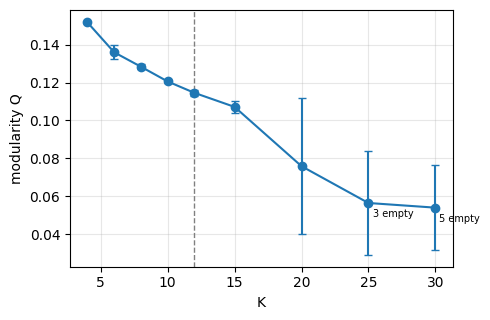

pgfplots coordinates: (4.0,0.1517) +- (0,0.0004) (6.0,0.1360) +- (0,0.0036) (8.0,0.1284) +- (0,0.0013) (10.0,0.1206) +- (0,0.0007) (12.0,0.1146) +- (0,0.0015) (15.0,0.1072) +- (0,0.0031) (20.0,0.0759) +- (0,0.0359) (25.0,0.0565) +- (0,0.0275) (30.0,0.0540) +- (0,0.0224)


In [8]:
ref = RUNS[("hetero", CONFIG["SEEDS"][0])]
Xref = torch.cat([torch.from_numpy(ref["z"]["U"].astype(np.float32)).to(device), ACT_t], 1)
sw = []
for k in CONFIG["K_SWEEP"]:
    for s in CONFIG["SWEEP_SEEDS"]:
        ids, _, secs, _ = run_dmon(Xref, k, s); sizes = np.bincount(ids, minlength=k)
        sw.append(dict(K=k, seed=s, Q=hard_modularity(ids), n_empty=int((sizes == 0).sum()), min_size=int(sizes[sizes > 0].min()), used=int((sizes > 0).sum())))
SW = pd.DataFrame(sw); SW.to_csv(f"{OUT}/k_sweep.csv", index=False)
SWa = SW.groupby("K").agg(Q=("Q", "mean"), Q_std=("Q", "std"), n_empty=("n_empty", "mean"), min_size=("min_size", "min"), used=("used", "mean")).reset_index()
print(SWa.round(4).to_string(index=False))
fig, ax = plt.subplots(figsize=(5, 3.3)); ax.errorbar(SWa.K, SWa.Q, yerr=SWa.Q_std.fillna(0), marker="o", capsize=3)
for _, r in SWa[SWa.n_empty > 0].iterrows(): ax.annotate(f"{r.n_empty:.0f} empty", (r.K, r.Q), fontsize=7, xytext=(3, -10), textcoords="offset points")
ax.axvline(CONFIG["K"], ls="--", c="gray", lw=1); ax.set_xlabel("K"); ax.set_ylabel("modularity Q"); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{OUT}/fig_k_sweep.pdf"); plt.savefig(f"{OUT}/fig_k_sweep.png", dpi=160); plt.show()
print("pgfplots coordinates:", " ".join(f"({r.K},{r.Q:.4f}) +- (0,{0 if pd.isna(r.Q_std) else r.Q_std:.4f})" for _, r in SWa.iterrows()))


## 7. What distinguishes the communities? 



reference partition: hetero seed 0 (Q = 0.1139)
structure (Q) vs content coherence (Cramér's V with sentiment/emotion; silhouette of author embeddings):
                 method    K      Q  cramers_v_sentiment  cramers_v_emotion  silhouette_content
          DMoN (hetero)   12 0.1139               0.1541             0.1531             -0.0548
       K-means (hetero)   12 0.0227               0.1434             0.1372              0.1053
               Spectral   12 0.0008               0.0248             0.0221              0.0456
                  METIS   12 0.2203               0.0552             0.0662             -0.0511
       Leiden (natural) 1044 0.2979               0.0901             0.0920             -0.3174
Louvain (natural, nb06) 1033 0.2675               0.0931             0.0986             -0.3005

    authors  documents  sent_Negative  sent_Neutral  sent_Positive  emo_Anger  emo_Joy  emo_Neutral  emo_Sadness  emo_Surprise  net_sentiment                                 

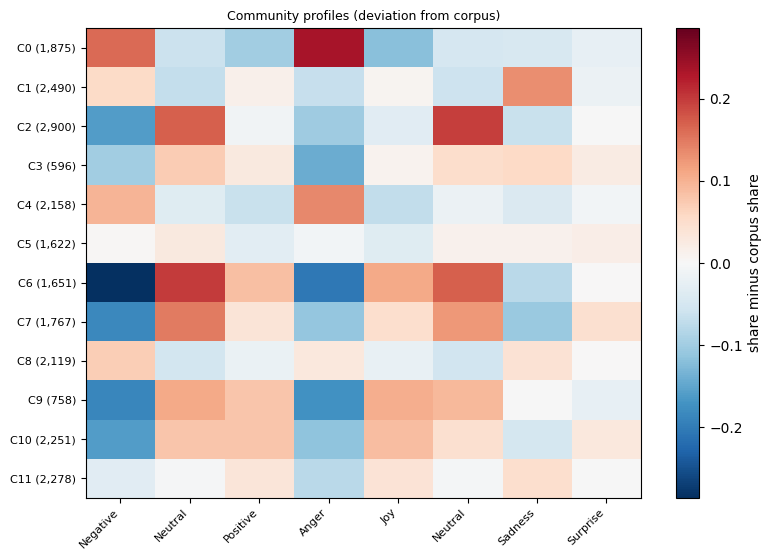

In [9]:
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
hq = R[(R.backbone == "hetero") & (R.method == "dmon")].sort_values("Q")
REF_SEED = int(hq.iloc[len(hq) // 2].seed); PART = RUNS[("hetero", REF_SEED)]["z"]["dmon"]
print(f"reference partition: hetero seed {REF_SEED} (Q = {hard_modularity(PART):.4f})")
lab_path = os.path.join(V2, "text_corpus_labeled_finetuned.parquet")
if not os.path.exists(lab_path): lab_path = os.path.join(CONFIG["BASE_DIR"], "text_corpus_labeled_finetuned.parquet")
lab = pd.read_parquet(lab_path)
pick = lambda key: "sentiment_label" if key == "sent" and "sentiment_label" in lab.columns else ("emotion_label" if key == "emo" and "emotion_label" in lab.columns else
       [c for c in lab.columns if key in c.lower() and not any(f in c.lower() for f in ("prob", "score", "conf"))][0])
lab = lab.set_index(lab["doc_id"].astype(str)).reindex(tc["doc_id"].astype(str))
S_lab = lab[pick("sent")].astype(str).str.capitalize().to_numpy(); E_lab = lab[pick("emo")].astype(str).str.capitalize().replace({"Fear": "Sadness"}).to_numpy()
comm_doc = np.where(doc_author >= 0, PART[np.maximum(doc_author, 0)], -1); okd = comm_doc >= 0
prof = pd.DataFrame({"community": comm_doc[okd], "sentiment": S_lab[okd], "emotion": E_lab[okd]})
P_s = pd.crosstab(prof.community, prof.sentiment, normalize="index"); P_e = pd.crosstab(prof.community, prof.emotion, normalize="index")
def cramers_v(ct):
    chi2 = stats.chi2_contingency(ct)[0]; n = ct.values.sum(); r, c = ct.shape
    return float(np.sqrt(chi2 / (n * (min(r, c) - 1))))
cv_s = cramers_v(pd.crosstab(prof.community, prof.sentiment)); cv_e = cramers_v(pd.crosstab(prof.community, prof.emotion))
sizes = pd.Series(PART).value_counts().sort_index(); ndocs = prof.community.value_counts().sort_index()
glob_s = prof.sentiment.value_counts(normalize=True)
# distinctive terms (c-TF-IDF)
extra_stop = {"https", "http", "www", "com", "amp", "gt", "lt", "removed", "deleted", "nbsp", "le", "la", "les", "de", "des", "et", "en", "un", "une",
              "du", "est", "pas", "que", "qui", "pour", "dans", "ce", "il", "je", "tu", "on", "au", "ne", "se", "sur", "avec", "mais", "ou",
              "w", "l", "f", "el", "fi", "li", "ya", "wa", "ana", "rak", "bach", "hadi", "had", "ga3", "ki", "kima", "wla", "3la", "m3a",
              "في", "من", "على", "ما", "لا", "و", "ان", "أن", "إن", "هذا", "هذه", "الى", "إلى", "عن", "مع", "كل", "هو", "هي", "او", "أو", "لي", "انا", "كان"}
docs_txt = tc["text"].fillna("").astype(str).to_numpy()[okd] if "text" in tc.columns else None
TERMS = {}
if docs_txt is not None:
    cv = CountVectorizer(max_features=CONFIG["MAX_FEATURES"], min_df=CONFIG["MIN_DF"], stop_words=list(ENGLISH_STOP_WORDS | extra_stop),
                         token_pattern=r"(?u)\b[^\W\d_][\w']{2,}\b", lowercase=True)
    Xc = cv.fit_transform(docs_txt); vocab_ = np.array(cv.get_feature_names_out())
    Kc = int(PART.max()) + 1; oh = sp.csr_matrix((np.ones(okd.sum()), (comm_doc[okd], np.arange(okd.sum()))), shape=(Kc, okd.sum()))
    tf = np.asarray((oh @ Xc).todense()); tf_n = tf / np.maximum(tf.sum(1, keepdims=True), 1)
    ctfidf = tf_n * np.log(1 + tf.sum(1).mean() / np.maximum(tf.sum(0), 1))
    for c in range(Kc): TERMS[c] = ", ".join(vocab_[np.argsort(-ctfidf[c])[:CONFIG["TOP_TERMS"]]])
CH = pd.DataFrame({"authors": sizes, "documents": ndocs}).fillna(0).astype(int)
for c in P_s.columns: CH[f"sent_{c}"] = P_s[c]
for c in P_e.columns: CH[f"emo_{c}"] = P_e[c]
CH["net_sentiment"] = CH.get("sent_Positive", 0) - CH.get("sent_Negative", 0)
CH["terms"] = pd.Series(TERMS)
CH.to_csv(f"{OUT}/community_profiles.csv")
# content coherence of EVERY partition: are communities distinguishable by what members write and feel?
from sklearn.metrics import silhouette_score
Uref = RUNS[("hetero", REF_SEED)]["z"]["U"].astype(np.float32); has_doc = np.abs(Uref).sum(1) > 0
def coherence(ids):
    ids = np.asarray(ids); cd = np.where(doc_author >= 0, ids[np.maximum(doc_author, 0)], -1)[okd]
    ct_s = pd.crosstab(cd, S_lab[okd]); ct_e = pd.crosstab(cd, E_lab[okd])
    sil = silhouette_score(Uref[has_doc], ids[has_doc], sample_size=min(5000, int(has_doc.sum())), random_state=0) if len(np.unique(ids[has_doc])) > 1 else np.nan
    return dict(cramers_v_sentiment=cramers_v(ct_s), cramers_v_emotion=cramers_v(ct_e), silhouette_content=float(sil))
parts = {"DMoN (hetero)": PART, "K-means (hetero)": RUNS[("hetero", REF_SEED)]["z"]["kmeans"]}
parts.update({k: v[0] for k, v in BASE.items()})
COH = pd.DataFrame([dict(method=k, K=int(len(np.unique(v))), Q=hard_modularity(v), **coherence(v)) for k, v in parts.items()])
COH.to_csv(f"{OUT}/partition_coherence.csv", index=False)
print("structure (Q) vs content coherence (Cramér's V with sentiment/emotion; silhouette of author embeddings):")
print(COH.round(4).to_string(index=False)); print()
pd.set_option("display.max_colwidth", 90); print(CH.round(3).to_string())
print(f"\nCramér's V (community x sentiment) = {cv_s:.3f}; (community x emotion) = {cv_e:.3f}; global net sentiment {glob_s.get('Positive', 0) - glob_s.get('Negative', 0):+.3f}")
fig, ax = plt.subplots(figsize=(8, 0.35 * len(CH) + 1.5))
H = pd.concat([P_s.sub(glob_s, axis=1), P_e.sub(prof.emotion.value_counts(normalize=True), axis=1)], axis=1)
im = ax.imshow(H.values, cmap="RdBu_r", vmin=-np.abs(H.values).max(), vmax=np.abs(H.values).max(), aspect="auto")
ax.set_xticks(range(H.shape[1])); ax.set_xticklabels(H.columns, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(H.shape[0])); ax.set_yticklabels([f"C{c} ({CH.authors[c]:,})" for c in H.index], fontsize=8)
plt.colorbar(im, label="share minus corpus share"); plt.title("Community profiles (deviation from corpus)", fontsize=9)
plt.tight_layout(); plt.savefig(f"{OUT}/fig_community_profiles.pdf"); plt.savefig(f"{OUT}/fig_community_profiles.png", dpi=160); plt.show()


## 8. Temporal dynamics: month-by-month re-assignment with the trained DMoN head
For every calendar month, each active author's embedding is the mean of **that month's** document representations from the reference backbone, concatenated with the static activity features. The trained reference DMoN head then assigns it to a community.

The results are:
- community sizes per month;
- membership stability between consecutive months, for authors active in both, compared with the stability expected by chance given the marginal community sizes;
- each static community's net sentiment per month.

  month  active_authors  agree_with_static  authors_in_both  stay_rate  chance_stay
2026-01            6817              0.783              NaN        NaN          NaN
2026-02            5099              0.711           2312.0      0.417        0.230
2026-03            5869              0.739           2151.0      0.449        0.253
2026-04            5679              0.707           2274.0      0.445        0.248
2026-05            5818              0.729           2277.0      0.418        0.236
2026-06            5694              0.761           2109.0      0.428        0.226

net sentiment (positive share - negative share) by month x community:
community     0      1      2      3      4      5      6      7      8      9      10     11
month                                                                                        
2026-01   -0.499 -0.241 -0.039 -0.113 -0.399 -0.260  0.141 -0.031 -0.326  0.039  0.034 -0.157
2026-02   -0.550 -0.282 -0.128 -0.080 -0.383 -0.267  0.137 

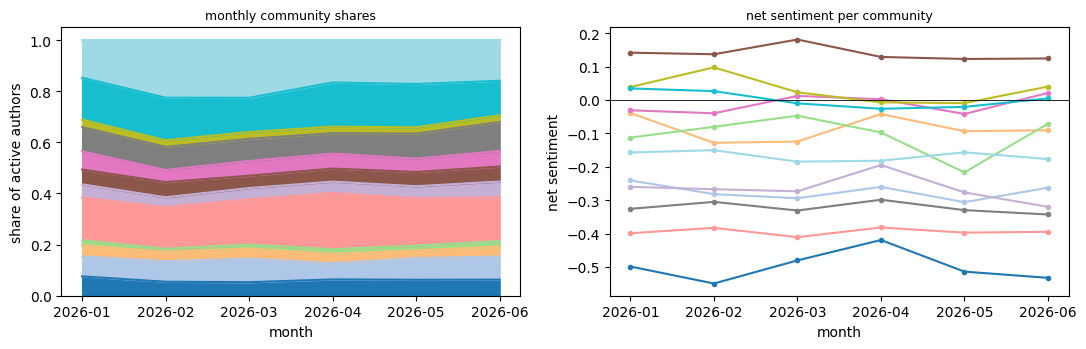

In [10]:
ref_tag = f"hetero_s{CONFIG['SEEDS'][0]}"
head = DMoNHead(Xref.shape[1], CONFIG["K"]).to(device); head.load_state_dict(torch.load(f"{OUT}/runs/dmon_head_{ref_tag}.pt", map_location=device)); head.eval()
doc_repr = torch.from_numpy(np.load(f"{OUT}/runs/doc_repr_{ref_tag}.npy").astype(np.float32)).to(device)
seen = torch.from_numpy(np.load(f"{OUT}/runs/doc_seen_{ref_tag}.npy")).to(device)
PART0 = RUNS[("hetero", CONFIG["SEEDS"][0])]["z"]["dmon"]
month = pd.to_datetime(tc["created_utc"], unit="s").dt.strftime("%Y-%m").to_numpy(); months = sorted(pd.unique(month))
assign, active = {}, {}
with torch.no_grad():
    for mth in months:
        msk = torch.from_numpy(month == mth).to(device)
        Um, cnt = pool_authors(doc_repr, seen, msk); act = (cnt > 0).cpu().numpy()
        if act.sum() < 10: continue
        ids = head(torch.cat([Um, ACT_t], 1)).argmax(1).cpu().numpy()
        assign[mth], active[mth] = ids, act
ms = list(assign.keys()); recs = []
for i, mth in enumerate(ms):
    sizes_m = np.bincount(assign[mth][active[mth]], minlength=CONFIG["K"])
    r = dict(month=mth, active_authors=int(active[mth].sum()),
             agree_with_static=float((assign[mth][active[mth]] == PART0[active[mth]]).mean()))
    if i > 0:
        both = active[mth] & active[ms[i - 1]]
        a, b = assign[ms[i - 1]][both], assign[mth][both]
        pa, pb = np.bincount(a, minlength=CONFIG["K"]) / max(len(a), 1), np.bincount(b, minlength=CONFIG["K"]) / max(len(b), 1)
        r.update(authors_in_both=int(both.sum()), stay_rate=float((a == b).mean()) if len(a) else np.nan, chance_stay=float(pa @ pb))
    for c in range(CONFIG["K"]): r[f"size_C{c}"] = int(sizes_m[c])
    recs.append(r)
TD = pd.DataFrame(recs); TD.to_csv(f"{OUT}/temporal_membership.csv", index=False)
print(TD[[c for c in TD.columns if not c.startswith("size_")]].round(3).to_string(index=False))
# net sentiment of each static community per month
comm0 = np.where(doc_author >= 0, PART0[np.maximum(doc_author, 0)], -1)
dfm = pd.DataFrame({"month": month, "community": comm0, "s": S_lab})
dfm = dfm[dfm.community >= 0]
NS = dfm.groupby(["month", "community"]).s.apply(lambda v: (v == "Positive").mean() - (v == "Negative").mean()).unstack()
NS.to_csv(f"{OUT}/temporal_net_sentiment.csv"); print("\nnet sentiment (positive share - negative share) by month x community:"); print(NS.round(3).to_string())
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
sz = TD.set_index("month")[[f"size_C{c}" for c in range(CONFIG["K"])]]
(sz.div(sz.sum(1), axis=0)).plot.area(ax=ax[0], legend=False, cmap="tab20"); ax[0].set_ylabel("share of active authors"); ax[0].set_title("monthly community shares", fontsize=9)
NS.plot(ax=ax[1], legend=False, cmap="tab20", marker="."); ax[1].axhline(0, c="k", lw=.6); ax[1].set_ylabel("net sentiment"); ax[1].set_title("net sentiment per community", fontsize=9)
plt.tight_layout(); plt.savefig(f"{OUT}/fig_temporal.pdf"); plt.savefig(f"{OUT}/fig_temporal.png", dpi=160); plt.show()


## 9. Cost (Table 3) and summary

In [11]:
cost = META.groupby("backbone").agg(backbone_train_min=("backbone_train_s", lambda s: s.mean() / 60), encode_pool_s=("encode_pool_s", "mean"),
                                    dmon_s=("dmon_s", "mean"), dmon_peak_mb=("dmon_peak_mb", "max")).reset_index()
cost.to_csv(f"{OUT}/cost.csv", index=False); print(cost.round(2).to_string(index=False))
fb = META.groupby("backbone")[["test_sent_f1", "test_emo_f1"]].agg(["mean", "std"]).round(3); print("\nbackbone forecasting (test macro-F1):\n", fb)
h = T[T.method.str.startswith("DMoN | hetero")].iloc[0]; kmh = T[T.method.str.startswith("K-means (graph-blind) | hetero")].iloc[0]
print(f"\nDMoN (Hetero, K={CONFIG['K']}): Q = {h.Q:.4f} +- {h.Q_std:.4f}, coverage {h.coverage:.3f}, conductance {h.mean_conductance:.3f}, ARI between runs {h.ARI_between_seeds:.2f}")
print(f"K-means (same input):  Q = {kmh.Q:.4f} -> ratio {h.Q / kmh.Q:.1f}x (notebook 06, leaky inputs: 5.1x)")
for _, b in BDF.iterrows(): print(f"{b.method:24s} K={b.K:5d}  Q = {b.Q:.4f}  coverage {b.coverage:.3f}  conductance {b.mean_conductance:.3f}")
print(f"Community x sentiment Cramér's V = {cv_s:.3f}; x emotion = {cv_e:.3f}")
print("Structure vs content, per method:"); print(COH.round(3).to_string(index=False))
if "stay_rate" in TD: print(f"Monthly membership stability: {TD.stay_rate.mean():.3f} vs chance {TD.chance_stay.mean():.3f}")
print("Artifacts:", sorted(os.listdir(OUT)))


backbone  backbone_train_min  encode_pool_s  dmon_s  dmon_peak_mb
  hetero                 1.7           4.13   10.86       1527.47
    lite                 1.7           4.11   10.82       1527.67

backbone forecasting (test macro-F1):
          test_sent_f1        test_emo_f1       
                 mean    std        mean    std
backbone                                       
hetero          0.453  0.006       0.312  0.007
lite            0.458  0.007       0.314  0.007

DMoN (Hetero, K=12): Q = 0.1140 +- 0.0013, coverage 0.361, conductance 0.853, ARI between runs 0.36
K-means (same input):  Q = 0.0178 -> ratio 6.4x (notebook 06, leaky inputs: 5.1x)
Spectral                 K=   12  Q = 0.0008  coverage 1.000  conductance 0.058
METIS                    K=   12  Q = 0.2203  coverage 0.324  conductance 0.694
Leiden (natural)         K= 1044  Q = 0.2979  coverage 0.484  conductance 0.089
Louvain (natural, nb06)  K= 1033  Q = 0.2675  coverage 0.405  conductance 0.084
Community x sentime